# Quando a chuva vira problema

**Chuva e ocorrências urbanas nos bairros do Rio de Janeiro**

Pedro Henrique Vasconcelos Neves e Gabriel Andrade Souza · Análise Exploratória de Dados e Visualização · FGV EMAp 2026.2

Quanta chuva, e em que lugar, vira problema no Rio? E por que a mesma chuva pode estar associada a impactos diferentes entre bairros? Investigamos essas perguntas combinando medições de pluviômetros, registros do Centro de Operações Rio (COR), limites de bairros e indicadores demográficos e sociais. Entender essas diferenças pode orientar perguntas sobre monitoramento e vulnerabilidade, respeitando as limitações das fontes.

**Neste marco intermediário**, apresentamos a definição e preparação dos dados, a cobertura espacial e temporal das medições, um primeiro retrato da sazonalidade em Vidigal e a associação das ocorrências aos bairros. Os resultados mostram que a composição da rede e a presença de dados variam ao longo da série. Em Vidigal, os meses completos de 2014–2021 apresentam médias mensais diferentes; 4.705 registros dos tipos inicialmente selecionados foram localizados em um bairro único.

O cruzamento entre chuva e ocorrências ainda não foi realizado. Por isso, esta entrega não estima um limiar de chuva nem compara a vulnerabilidade dos bairros; esses objetivos orientam as etapas seguintes.

**Repositório do projeto:** [Quando_a_chuva_vira_problema no GitHub](https://github.com/PedroVNeves/Quando_a_chuva_vira_problema).


### Hipóteses e escopo do marco 2

As hipóteses abaixo orientam a exploração e podem ser refinadas conforme conhecermos as bases. Não são conclusões antecipadas.

| Hipótese | Comparação proposta | Situação nesta entrega |
|---|---|---|
| **H1. A distribuição da chuva varia entre os meses do ano.** | Comparar totais mensais em períodos com cobertura adequada, começando por uma estação. | Exploramos Vidigal em 2014–2021, com 79 meses completos; o resultado ainda não representa a cidade toda. |
| **H2. Dias com mais chuva apresentam maior frequência de registros de acúmulo de água.** | Comparar a proporção de dias com ocorrência entre faixas de precipitação, incluindo dias sem ocorrências e com medição válida. | Tipos de ocorrência definidos; associação às medições de chuva ainda pendente. |
| **H3. A relação entre chuva e registros de ocorrência varia entre bairros.** | Comparar frequências em condições semelhantes de chuva e cobertura; depois explorar a associação com indicadores sociais. | Associação espacial aos bairros realizada; comparação condicionada à chuva e integração do perfil social ainda pendentes. |

As sete perguntas de domínio da seção 4 permanecem como roteiro do projeto final. Neste marco, o foco é demonstrar viabilidade, decisões de preparação e resultados descritivos iniciais. A pergunta sobre tempo de resposta dependerá de verificar se os campos disponíveis medem chegada dos órgãos; a diferença entre início e fim, sozinha, mede duração registrada.


## 1. De onde vêm os dados

| Base | Fonte | O que tem |
|---|---|---|
| Chuva | Pluviômetros do [Sistema Alerta Rio](https://www.sistema-alerta-rio.com.br/download/dados-meteorologicos/) | Acumulados de 15 min a 96 h, a cada 15 min, desde 1997 |
| Ocorrências | [Centro de Operações Rio (COR)](https://cor.rio/historia/), [publicadas no datalake](https://cor.rio/prefeitura-do-rio-lanca-dados-do-cor-em-datalake-disponivel-ao-cidadao/) | Cada evento registrado: tipo, gravidade, local, início e fim, órgãos acionados |
| Bairros | Limites de bairro do IPP (datalake da prefeitura) | Polígono de cada bairro |
| Censo 2022 | [Censo 2022 por bairro](https://www.data.rio/datasets/fd354740f1934bf5bf8e9b0e2b509aa9_2/about) (IBGE, agregado pelo IPP) | População e domicílios |
| IPS 2022 | [IPS Bairros 2022](https://ips-rio-pcrj.hub.arcgis.com/pages/ipsbairros) | Índice de Progresso Social e indicadores como população em favelas não urbanizadas e domicílios inadequados |

Chuva, ocorrências e bairros estão no **datalake público da prefeitura** (BigQuery, projeto `datario`). Censo e IPS estão no **Data.Rio**.

## 2. Baixando

O datalake é público: basta uma conta Google e uma consulta SQL. Por exemplo:

```python
pandas_gbq.read_gbq("SELECT * FROM `datario.adm_cor_comando.ocorrencias`", project_id="<seu projeto>")
```

Para não repetir o download, guardamos tudo em `dados/brutos/` com dois scripts (cerca de 1,5 GB):

In [40]:
# Já rodado; descomentar para baixar de novo
# !python scripts/baixar_datario.py
# !python scripts/baixar_data_rio.py

## 3. Uma olhada nos dados

In [41]:
from datetime import date
from pathlib import Path

import geopandas as gpd
import pandas as pd

pd.set_option("display.max_columns", None)

BQ = Path("dados/brutos/bigquery")
DATA_RIO = Path("dados/brutos/data_rio")

### Cobertura e qualidade dos dados

Antes de explorar as relações entre chuva e ocorrências, conferimos a cobertura das bases completas e a ausência de campos essenciais. Nas ocorrências, usamos a data de início no horário do Rio; na chuva, a data registrada em `data_particao`. O recorte comum é a interseção desses períodos, sem presumir que todos os dias e estações tenham medições completas.

Os percentuais abaixo contam registros com data ausente (data ou horário, na chuva) e com pelo menos uma coordenada ausente. As coordenadas dos pluviômetros ficam no cadastro de estações, não nas leituras. Esta etapa apenas descreve os dados, sem excluir registros.


In [42]:
import pyarrow.compute as pc
import pyarrow.parquet as pq

# Colunas da base original, antes de qualquer junção ou filtro.
cor_cobertura = pd.read_parquet(
    BQ / "adm_cor_comando" / "ocorrencias.parquet",
    columns=["data_inicio", "latitude", "longitude"],
)
estacoes_cobertura = pd.read_parquet(
    BQ / "clima_pluviometro" / "estacoes_alertario.parquet",
    columns=["id_estacao", "latitude", "longitude"],
)
datas_cor = cor_cobertura["data_inicio"].dt.tz_convert("America/Sao_Paulo").dt.date
coords_cor_ausentes = cor_cobertura[["latitude", "longitude"]].isna().any(axis=1)
coords_estacoes_ausentes = estacoes_cobertura[["latitude", "longitude"]].isna().any(axis=1)

# Referência fixa para tornar a identificação de datas futuras reproduzível.
data_referencia = date(2026, 10, 28)
datas_chuva_futuras = 0

# A série inteira de chuva é lida em lotes, usando apenas três colunas.
arquivo_chuva = pq.ParquetFile(BQ / "clima_pluviometro" / "taxa_precipitacao_alertario.parquet")
inicio_chuva, fim_chuva = None, None
n_chuva, datas_chuva_ausentes = 0, 0
ids_estacoes_chuva = set()
for lote in arquivo_chuva.iter_batches(columns=["data_particao", "horario", "id_estacao"]):
    n_chuva += lote.num_rows
    limites = pc.min_max(lote["data_particao"]).as_py()
    if limites["min"] is not None:
        inicio_chuva = min(inicio_chuva, limites["min"]) if inicio_chuva else limites["min"]
        fim_chuva = max(fim_chuva, limites["max"]) if fim_chuva else limites["max"]
    datas_chuva_ausentes += pc.sum(
        pc.or_(pc.is_null(lote["data_particao"]), pc.is_null(lote["horario"]))
    ).as_py()
    datas_chuva_futuras += pc.sum(
        pc.fill_null(pc.greater(lote["data_particao"], data_referencia), False)
    ).as_py()
    ids_estacoes_chuva.update(pc.unique(lote["id_estacao"]).to_pylist())
ids_estacoes_chuva.discard(None)

inicio_cor, fim_cor = datas_cor.dropna().min(), datas_cor.dropna().max()
cobertura = pd.DataFrame([
    {"Base": "Ocorrências COR", "Registros": len(cor_cobertura),
     "Início": inicio_cor, "Fim": fim_cor, "Estações": "Não se aplica",
     "Datas ausentes (%)": datas_cor.isna().mean() * 100,
     "Datas futuras (n)": int((datas_cor.dropna() > data_referencia).sum()),
     "Coordenadas ausentes (%)": round(coords_cor_ausentes.mean() * 100, 2)},
    {"Base": "Chuva Alerta Rio", "Registros": n_chuva,
     "Início": inicio_chuva, "Fim": fim_chuva, "Estações": len(ids_estacoes_chuva),
     "Datas ausentes (%)": 100 * datas_chuva_ausentes / n_chuva,
     "Datas futuras (n)": datas_chuva_futuras,
     "Coordenadas ausentes (%)": "Ver cadastro"},
])
display(cobertura.round(2))
print(f"Cadastro: {len(estacoes_cobertura)} estações; "
      f"{coords_estacoes_ausentes.mean():.2%} com coordenadas ausentes.")

inicio_comum, fim_comum = max(inicio_cor, inicio_chuva), min(fim_cor, fim_chuva)
if inicio_comum <= fim_comum:
    print(f"Recorte comum adotado para os próximos cruzamentos: {inicio_comum:%d/%m/%Y} a {fim_comum:%d/%m/%Y}.")
else:
    print("As bases não têm sobreposição temporal; é necessário rever o recorte.")


,Base,Registros,Início,Fim,Estações,Datas ausentes (%),Datas futuras (n),Coordenadas ausentes (%)
0,Ocorrências COR,91406,2015-02-23,2024-04-02,Não se aplica,0.00,0,0.2
1,Chuva Alerta Rio,29345149,1997-01-01,2099-03-03,33,0.02,1,Ver cadastro


Cadastro: 37 estações; 10.81% com coordenadas ausentes.
Recorte comum adotado para os próximos cruzamentos: 23/02/2015 a 02/04/2024.


**Como interpretar:** início e fim indicam a extensão observada dos arquivos, não cobertura contínua. Zero de chuva é uma medição válida e não deve ser confundido com ausência de leitura. O percentual de coordenadas ausentes também não verifica se os pontos estão dentro do município. Antes dos cruzamentos, ainda será necessário avaliar lacunas por estação, coordenadas inválidas e compatibilidade dos horários entre as fontes. O recorte comum substitui a previsão de 2015–2025 da proposta; a série mais longa de chuva pode ser usada separadamente na análise climática.

**Alerta encontrado:** há datas de chuva chegando a 2099, posteriores à referência de 28/10/2026. Elas foram contadas como datas futuras. A subseção seguinte documenta a inspeção e o tratamento para as análises, preservando a base bruta.


### Tratamento da data futura na chuva

Inspecionamos o registro posterior à referência de 28/10/2026 e as últimas leituras com datas não futuras da mesma estação. A inspeção usa a base bruta e não altera o arquivo.


In [43]:
import pyarrow.dataset as ds

base_chuva = ds.dataset(
    BQ / "clima_pluviometro" / "taxa_precipitacao_alertario.parquet",
    format="parquet",
)
filtro_futuro = ds.field("data_particao") > data_referencia
registros_futuros = base_chuva.to_table(filter=filtro_futuro).to_pandas()
display(registros_futuros)

# Contexto: últimas três leituras distintas, com data não futura, da estação afetada.
ids_afetados = registros_futuros["id_estacao"].dropna().unique().tolist()
ultimas_leituras = base_chuva.to_table(
    columns=["primary_key", "data_particao", "horario", "acumulado_chuva_24_h"],
    filter=(ds.field("id_estacao").isin(ids_afetados))
    & (ds.field("data_particao") <= data_referencia),
).to_pandas().drop_duplicates().sort_values(["data_particao", "horario"]).tail(3)
display(ultimas_leituras)

# Visão para as análises: exclui apenas datas futuras; ausências ficam para outra etapa.
# O filtro é aplicado na leitura e não regrava o Parquet bruto.
chuva_para_analise = base_chuva.filter(
    (ds.field("data_particao") <= data_referencia)
    | ds.field("data_particao").is_null()
)
print(f"Registros com data futura excluídos da análise: {len(registros_futuros)}.")
print(f"Registros restantes: {chuva_para_analise.count_rows():,}.")


,primary_key,id_estacao,acumulado_chuva_15_min,acumulado_chuva_1_h,acumulado_chuva_4_h,acumulado_chuva_24_h,acumulado_chuva_96_h,horario,data_particao
0,28_2099-03-03 03:30:00,28,NaN,NaN,NaN,NaN,NaN,03:30:00,2099-03-03


,primary_key,data_particao,horario,acumulado_chuva_24_h
178665,28_2024-06-02 23:45:00,2024-06-02,23:45:00,0.0
196872,28_2024-06-02 23:50:00,2024-06-02,23:50:00,0.0
34105,28_2024-06-03 00:00:00,2024-06-03,00:00:00,0.0


Registros com data futura excluídos da análise: 1.
Registros restantes: 29,345,148.


**Decisão:** o único registro futuro é da estação 28 (Alto da Boa Vista), em 03/03/2099 às 03:30. A própria `primary_key` contém essa data e todos os cinco acumulados de chuva estão ausentes. As últimas leituras não futuras da estação chegam a 03/06/2024; isso não permite deduzir a data correta do registro. Por isso, não imputamos uma data: excluímos datas posteriores à referência de 28/10/2026 da visão `chuva_para_analise`, usada nas leituras seguintes. A tabela de cobertura acima continua descrevendo a base bruta, inclusive a anomalia. Nenhum outro tratamento de qualidade foi aplicado aqui.


### Diagnóstico de duplicatas na chuva

Usamos a visão sem datas futuras, sem remover outras linhas. Uma chave de leitura é a combinação de estação, data e horário. Contamos separadamente as cópias excedentes de linhas totalmente idênticas e as chaves com valores diferentes em pelo menos um dos cinco acumulados de chuva. Um valor ausente e um valor preenchido também contam como diferença. Chaves incompletas são contadas à parte e não entram na comparação por horário.


In [44]:
# Uma estação por vez limita o uso de memória e encontra repetições entre lotes.
chaves_leitura = ["id_estacao", "data_particao", "horario"]
acumulados = [c for c in chuva_para_analise.schema.names if c.startswith("acumulado_chuva_")]
resumos_duplicatas = []
exemplos_identicos, exemplos_conflitos = [], []
for id_estacao in sorted(ids_estacoes_chuva) + [None]:
    filtro_estacao = (ds.field("id_estacao").is_null() if id_estacao is None
                      else ds.field("id_estacao") == id_estacao)
    leituras = chuva_para_analise.to_table(filter=filtro_estacao).to_pandas()
    if leituras.empty:
        continue
    repetidas = leituras.duplicated(keep=False)
    copias_excedentes = int(leituras.duplicated().sum())
    completas = leituras.dropna(subset=chaves_leitura)
    tamanhos = completas.groupby(chaves_leitura).size()
    distintas = completas.drop_duplicates()
    grupos = distintas.groupby(chaves_leitura)
    conflitos = grupos[acumulados].nunique(dropna=False).gt(1).any(axis=1)
    variantes = grupos.size()
    resumos_duplicatas.append({
        "Registros examinados": len(leituras),
        "Registros com chave incompleta": len(leituras) - len(completas),
        "Cópias idênticas excedentes": copias_excedentes,
        "Chaves com mais de um registro": int(tamanhos.gt(1).sum()),
        "Chaves com acumulados diferentes": int(conflitos.sum()),
        "Chaves com diferença apenas em outros campos": int(((variantes > 1) & ~conflitos).sum()),
    })
    if repetidas.any() and not exemplos_identicos:
        exemplos_identicos.append(leituras.loc[repetidas].drop_duplicates().head(3))
    if conflitos.any() and not exemplos_conflitos:
        chaves_exemplo = conflitos[conflitos].head(2).reset_index()[chaves_leitura]
        exemplos_conflitos.append(
            distintas.merge(chaves_exemplo, on=chaves_leitura).sort_values(chaves_leitura)
        )

resumo_duplicatas = pd.DataFrame(resumos_duplicatas).sum().rename("Quantidade").to_frame()
display(resumo_duplicatas)
print("Exemplos de linhas que aparecem mais de uma vez (cada linha exibida uma única vez):")
if exemplos_identicos:
    display(exemplos_identicos[0])
else:
    print("Nenhuma linha idêntica repetida encontrada.")
print("Exemplos de valores diferentes para a mesma estação, data e horário:")
if exemplos_conflitos:
    display(exemplos_conflitos[0])
else:
    print("Nenhum conflito nos acumulados encontrado.")


,Quantidade
Registros examinados,29345148
Registros com chave incompleta,7178
Cópias idênticas excedentes,99
Chaves com mais de um registro,33
Chaves com acumulados diferentes,0
Chaves com diferença apenas em outros campos,0


Exemplos de linhas que aparecem mais de uma vez (cada linha exibida uma única vez):


,primary_key,id_estacao,acumulado_chuva_15_min,acumulado_chuva_1_h,acumulado_chuva_4_h,acumulado_chuva_24_h,acumulado_chuva_96_h,horario,data_particao
3478,1_2024-06-03 00:00:00,1,0.0,0.0,0.0,0.0,9.4,00:00:00,2024-06-03


Exemplos de valores diferentes para a mesma estação, data e horário:
Nenhum conflito nos acumulados encontrado.


**Resultado:** nos 29.345.148 registros sem datas futuras, encontramos 99 cópias idênticas excedentes, distribuídas em 33 chaves repetidas. Nenhuma chave completa apresentou acumulados diferentes ou diferenças apenas em outros campos. Outros 7.178 registros têm chave incompleta e não permitem a mesma comparação por estação e horário.

**Como interpretar:** cópias excedentes contam as linhas além da primeira ocorrência idêntica. As contagens por chave medem grupos de leituras, não linhas; uma chave com valores conflitantes também pode conter cópias idênticas. Diferenças apenas em outros campos são reportadas separadamente para não confundi-las com divergências na chuva. Os exemplos ilustram casos encontrados e não representam toda a série. Este diagnóstico não altera `chuva_para_analise` nem o arquivo bruto; qualquer decisão de deduplicação ficará para uma mudança separada.


### Remoção de cópias idênticas na leitura

A partir daqui, as leituras para análise passam pela função abaixo. Ela compara todas as colunas e mantém uma cópia de cada linha idêntica, sem escolher entre valores diferentes para a mesma estação e horário. O filtro de datas futuras continua sendo aplicado pela visão anterior. O Parquet bruto e o diagnóstico acima permanecem intactos.


In [45]:
def ler_chuva_para_analise(filtro):
    # Informe um recorte (por estação ou período) para limitar o uso de memória.
    # Todas as colunas participam da comparação, inclusive as que contêm ausências.
    return chuva_para_analise.to_table(filter=filtro).to_pandas().drop_duplicates()


# Verifica a série inteira por estação, sem carregá-la toda de uma vez.
n_antes_deduplicacao = chuva_para_analise.count_rows()
n_apos_deduplicacao = 0
n_chaves_incompletas_apos = 0
for id_estacao in sorted(ids_estacoes_chuva) + [None]:
    filtro_estacao = (ds.field("id_estacao").is_null() if id_estacao is None
                      else ds.field("id_estacao") == id_estacao)
    leituras_unicas = ler_chuva_para_analise(filtro_estacao)
    n_apos_deduplicacao += len(leituras_unicas)
    n_chaves_incompletas_apos += int(
        leituras_unicas[["id_estacao", "data_particao", "horario"]].isna().any(axis=1).sum()
    )

print(f"Registros antes: {n_antes_deduplicacao:,}.")
print(f"Cópias idênticas removidas: {n_antes_deduplicacao - n_apos_deduplicacao}.")
print(f"Registros após: {n_apos_deduplicacao:,}.")
print(f"Registros com chave incompleta preservados: {n_chaves_incompletas_apos:,}.")


Registros antes: 29,345,148.
Cópias idênticas removidas: 99.
Registros após: 29,345,049.
Registros com chave incompleta preservados: 7,178.


**Resultado:** a leitura passa de 29.345.148 para 29.345.049 registros, removendo somente as 99 cópias idênticas excedentes. Os 7.178 registros com chave incompleta permanecem disponíveis para investigação separada. A função deve ser usada nas próximas leituras de chuva; ela não grava uma nova base nem modifica a visão usada no diagnóstico.


### O que falta nos registros com chave incompleta?

Inspecionamos os registros sem estação, data ou horário usando a função de leitura sem datas futuras e sem cópias idênticas. A primeira tabela conta as combinações de ausências observadas; a segunda verifica cada campo e os cinco acumulados. Valores de chuva iguais a zero são considerados preenchidos. Os exemplos mostram até três registros de cada combinação de ausências, sem alterar a base.


In [ ]:
filtro_chave_incompleta = (
    ds.field("id_estacao").is_null()
    | ds.field("data_particao").is_null()
    | ds.field("horario").is_null()
)
chuva_chave_incompleta = ler_chuva_para_analise(filtro_chave_incompleta)
campos_chave = ["id_estacao", "data_particao", "horario"]
campos_chuva = [c for c in chuva_chave_incompleta.columns if c.startswith("acumulado_chuva_")]
ausencias_chave = chuva_chave_incompleta[campos_chave].isna()

print("Combinações de ausências (True = campo ausente):")
padroes_ausencia = ausencias_chave.value_counts().rename("Registros").reset_index()
display(padroes_ausencia)

print("Preenchimento dos campos entre os registros com chave incompleta:")
campos_diagnostico = chuva_chave_incompleta[campos_chave + campos_chuva]
preenchimento_incompletas = pd.DataFrame({
    "Ausentes (n)": campos_diagnostico.isna().sum(),
    "Preenchidos (n)": campos_diagnostico.notna().sum(),
})
display(preenchimento_incompletas)
todos_acumulados = chuva_chave_incompleta[campos_chuva].notna().all(axis=1)
nenhum_acumulado = chuva_chave_incompleta[campos_chuva].isna().all(axis=1)
print(f"Registros examinados: {len(chuva_chave_incompleta):,}.")
print(f"Com os cinco acumulados preenchidos: {todos_acumulados.sum():,}.")
print(f"Sem nenhum acumulado preenchido: {nenhum_acumulado.sum():,}.")

# As combinações são usadas apenas para selecionar exemplos, sem modificar a série.
rotulos_ausencia = ausencias_chave.apply(
    lambda linha: ", ".join(linha.index[linha]), axis=1,
)
exemplos_incompletas = chuva_chave_incompleta.assign(campos_ausentes=rotulos_ausencia)
print("Exemplos por combinação de campos ausentes:")
display(exemplos_incompletas.groupby("campos_ausentes", sort=True).head(3))


Combinações de ausências (True = campo ausente):


,id_estacao,data_particao,horario,Registros
0,False,False,True,7178


Preenchimento dos campos entre os registros com chave incompleta:


,Ausentes (n),Preenchidos (n)
id_estacao,0,7178
data_particao,0,7178
horario,7178,0
acumulado_chuva_15_min,6,7172
acumulado_chuva_1_h,7,7171
acumulado_chuva_4_h,7,7171
acumulado_chuva_24_h,2,7176
acumulado_chuva_96_h,1,7177


Registros examinados: 7,178.
Com os cinco acumulados preenchidos: 7,155.
Sem nenhum acumulado preenchido: 0.
Exemplos por combinação de campos ausentes:


,primary_key,id_estacao,acumulado_chuva_15_min,acumulado_chuva_1_h,acumulado_chuva_4_h,acumulado_chuva_24_h,acumulado_chuva_96_h,horario,data_particao,campos_ausentes
0,1_2023-10-11,1,0.0,0.2,0.2,0.8,44.8,None,2023-10-11,horario
1,1_2023-10-20,1,0.0,0.0,0.0,3.0,28.6,None,2023-10-20,horario
2,1_2023-09-25,1,0.0,0.0,0.0,0.0,0.0,None,2023-09-25,horario


**Resultado:** todos os 7.178 registros têm estação e data preenchidas, mas estão sem horário. Desses, 7.155 têm os cinco acumulados preenchidos e 0 não têm nenhum acumulado preenchido. Portanto, chave incompleta não significa ausência das medições de chuva.

**Implicação:** esses registros não permitem associar diretamente uma ocorrência ao horário da medição ou ordenar leituras dentro do dia. Ter a data preenchida, por si só, não garante que a leitura seja adequada a uma agregação diária; o tratamento dependerá da medida escolhida. Nenhum horário foi imputado e nenhum registro foi excluído neste diagnóstico.


### Leitura para cruzamentos temporais

Para associar chuva e ocorrências no tempo, exigimos estação, data e horário preenchidos. A função específica abaixo mantém os tratamentos anteriores e aplica esse requisito apenas à leitura solicitada. A função geral continua disponível, inclusive para investigar os registros sem horário. Ter uma chave completa não garante ausência de lacunas na série nem de valores ausentes nos acumulados.


In [ ]:
def ler_chuva_com_horario(filtro):
    chave_completa = (
        ds.field("id_estacao").is_valid()
        & ds.field("data_particao").is_valid()
        & ds.field("horario").is_valid()
    )
    return ler_chuva_para_analise(filtro & chave_completa)


# Contagem derivada da conferência da série inteira na etapa de deduplicação.
n_disponiveis_temporais = n_apos_deduplicacao - n_chaves_incompletas_apos
print(f"Leitura geral, após deduplicação: {n_apos_deduplicacao:,} registros.")
print(f"Fora dos cruzamentos temporais por chave incompleta: {n_chaves_incompletas_apos:,}.")
print(f"Disponíveis com chave completa: {n_disponiveis_temporais:,}.")

# Exemplo em um dia que contém registros sem horário; nenhuma data é imputada.
filtro_dia_exemplo = ds.field("data_particao") == date(2023, 10, 11)
exemplo_geral = ler_chuva_para_analise(filtro_dia_exemplo)
exemplo_temporal = ler_chuva_com_horario(filtro_dia_exemplo)
print(f"Em 11/10/2023: {len(exemplo_geral)} registros na leitura geral "
      f"e {len(exemplo_temporal)} na leitura para cruzamentos temporais.")
print("Chaves incompletas no exemplo temporal:",
      int(exemplo_temporal[["id_estacao", "data_particao", "horario"]].isna().any(axis=1).sum()))


Leitura geral, após deduplicação: 29,345,049 registros.
Fora dos cruzamentos temporais por chave incompleta: 7,178.
Disponíveis com chave completa: 29,337,871.
Em 11/10/2023: 3134 registros na leitura geral e 3101 na leitura para cruzamentos temporais.
Chaves incompletas no exemplo temporal: 0


**Uso daqui em diante:** `ler_chuva_com_horario(filtro)` será usada nos cruzamentos com horários de ocorrências; `ler_chuva_para_analise(filtro)` continua sendo a leitura geral. São 29.337.871 registros com chave completa. Os 7.178 sem horário permanecem preservados na leitura geral e no arquivo bruto. A padronização dos fusos horários e a escolha da janela de chuva serão verificadas na etapa de integração das bases.


### Ocorrências do COR

In [46]:
# Um evento por linha, de 2015 a abril de 2024
ocorrencias = pd.read_parquet(BQ / "adm_cor_comando" / "ocorrencias.parquet")
print(ocorrencias.shape)
ocorrencias.head()

(91406, 13)


,id_pop,id_evento,bairro,data_inicio,data_fim,prazo,descricao,gravidade,latitude,longitude,status,tipo,data_particao
0,1,10707,NaN,2016-10-01 18:58:16+00:00,2016-10-01 19:37:23+00:00,NaN,Autoestrada grajaú - jacarepaguá - km 4 - jaca...,Baixo,-22.916662,-43.262981,Fechado,Primario,2016-10-01
1,1,10693,NaN,2016-10-01 12:31:53+00:00,2016-10-01 13:07:23+00:00,NaN,"R. andré rocha, 1025 b - taquara",Baixo,-22.925347,-43.370468,Fechado,Primario,2016-10-01
2,1,10701,NaN,2016-10-01 17:01:26+00:00,2016-10-01 17:44:41+00:00,NaN,"Estr. das capoeiras, 80 - campo grande",Baixo,-22.895124,-43.558608,Fechado,Primario,2016-10-01
3,1,10708,NaN,2016-10-01 19:32:56+00:00,2016-10-01 20:07:42+00:00,NaN,"Av. das américas, 12600 - barra da tijuca",Baixo,-23.002726,-43.426523,Fechado,Primario,2016-10-01
4,1,10700,NaN,2016-10-01 17:00:14+00:00,2016-10-01 17:45:07+00:00,NaN,"Av. das américas, 3959 - barra",Baixo,-23.001086,-43.352867,Fechado,Primario,2016-10-01


In [47]:
# O tipo de evento vem como código (id_pop); outra tabela dá o nome de cada código
pop = pd.read_parquet(BQ / "adm_cor_comando" / "procedimento_operacional_padrao.parquet")
ocorrencias = ocorrencias.merge(pop, on="id_pop", how="left")
ocorrencias["pop_titulo"].value_counts().head(10)

pop_titulo
Acidente/enguiço sem vítima              41611
Acidente com vítima(s)                   19286
Operação policial                         5060
Bolsão d'água em via                      4231
Queda de árvore                           3695
Obra em local público                     2945
Atropelamento                             2430
Evento em local público ou particular     2277
Manifestação em local público             2192
Incêndio em veículo(s)                    1300
Name: count, dtype: int64

### Quais tipos de ocorrência vamos comparar com a chuva?

Catalogamos os tipos efetivamente registrados no COR antes de selecionar eventos. O foco descritivo inicial reúne rótulos de acúmulo de água (bolsão d'água, alagamentos, enchente e lâmina d'água) e, separadamente, deslizamentos. Essa classificação pelo rótulo não demonstra que cada registro foi provocado por chuva.

Outros tipos, como quedas de árvores, continuam disponíveis e podem ser investigados depois. As contagens abaixo são de registros da base inteira, ainda sem filtros de período comum, coordenadas ou duplicidade de eventos. Tipos sem descrição no cadastro são apresentados explicitamente.


In [ ]:
# Catálogo por código: contamos a base original para não depender de outras junções.
tipos_cor = pd.read_parquet(
    BQ / "adm_cor_comando" / "ocorrencias.parquet", columns=["id_pop"],
)
catalogo_cor = tipos_cor["id_pop"].value_counts(dropna=False).rename_axis("id_pop").reset_index(name="Registros")
catalogo_cor = catalogo_cor.merge(pop, on="id_pop", how="left", validate="one_to_one")
catalogo_cor["Tipo"] = catalogo_cor["pop_titulo"].fillna("Sem descrição no cadastro")

# Agrupamento inicial para orientar as comparações; nenhuma linha é excluída.
grupo_foco_cor = {
    "5": "Acúmulo de água", "6": "Acúmulo de água", "31": "Acúmulo de água",
    "32": "Acúmulo de água", "33": "Acúmulo de água", "28": "Deslizamentos",
}
catalogo_cor["Grupo inicial"] = catalogo_cor["id_pop"].map(grupo_foco_cor).fillna("Outros tipos, preservados")
catalogo_cor.loc[catalogo_cor["pop_titulo"].isna(), "Grupo inicial"] = "Sem descrição no cadastro"
catalogo_cor["Participação (%)"] = (100 * catalogo_cor["Registros"] / len(tipos_cor)).round(2)
display(catalogo_cor[["id_pop", "Tipo", "Registros", "Participação (%)", "Grupo inicial"]])

resumo_grupos_cor = catalogo_cor.groupby("Grupo inicial")["Registros"].sum().sort_values(ascending=False).to_frame()
display(resumo_grupos_cor)
print(f"Total conferido: {catalogo_cor['Registros'].sum():,} registros.")


,id_pop,Tipo,Registros,Participação (%),Grupo inicial
0,1,Acidente/enguiço sem vítima,41611,45.52,"Outros tipos, preservados"
1,2,Acidente com vítima(s),19286,21.10,"Outros tipos, preservados"
2,26,Operação policial,5060,5.54,"Outros tipos, preservados"
3,5,Bolsão d'água em via,4231,4.63,Acúmulo de água
4,11,Queda de árvore,3695,4.04,"Outros tipos, preservados"
5,25,Obra em local público,2945,3.22,"Outros tipos, preservados"
6,22,Atropelamento,2430,2.66,"Outros tipos, preservados"
7,21,Evento em local público ou particular,2277,2.49,"Outros tipos, preservados"
8,7,Manifestação em local público,2192,2.40,"Outros tipos, preservados"
9,4,Incêndio em veículo(s),1300,1.42,"Outros tipos, preservados"


,Registros
Grupo inicial,
"Outros tipos, preservados",86322
Acúmulo de água,4882
Deslizamentos,176
Sem descrição no cadastro,26


Total conferido: 91,406 registros.


**Resultado:** há 4.882 registros nos tipos de acúmulo de água e 176 de deslizamentos, antes dos demais critérios de análise. Outros 26 registros não têm descrição correspondente no cadastro de tipos: 24 usam o código 99 e dois estão sem código. Eles permanecem na base e não serão classificados por suposição.

**Próxima comparação:** depois de conferir coordenadas e datas, esses grupos poderão ser comparados com a chuva, mantendo os tipos individuais disponíveis. Um número maior de registros, sozinho, não indica maior risco: será necessário considerar a cobertura, o período e a intensidade da chuva. Nenhum filtro de seleção de ocorrências foi aplicado nesta etapa.


### Coordenadas e datas das ocorrências do foco inicial

Conferimos os registros dos grupos de acúmulo de água e deslizamentos antes de associá-los à chuva. Para o cruzamento espacial e temporal, verificamos início preenchido no recorte comum e coordenadas presentes, dentro das faixas geográficas e dos limites de bairros disponíveis. Pontos na borda também são aceitos. Esse teste não substitui a associação a um bairro ou a uma estação.

A data final é verificada separadamente para futuras análises de duração: sua ausência ou uma duração negativa não impedem, por si só, o uso do início no cruzamento com chuva. As contagens são de registros, sem resolver possíveis repetições de eventos. Nenhuma linha é removida da base.


In [ ]:
cor_foco_qualidade = pd.read_parquet(BQ / "adm_cor_comando" / "ocorrencias.parquet")
cor_foco_qualidade = cor_foco_qualidade.loc[
    cor_foco_qualidade["id_pop"].isin(grupo_foco_cor)
].copy()
cor_foco_qualidade["Grupo inicial"] = cor_foco_qualidade["id_pop"].map(grupo_foco_cor)
inicio_local_cor = cor_foco_qualidade["data_inicio"].dt.tz_convert("America/Sao_Paulo")
inicio_no_recorte_cor = inicio_local_cor.dt.date.between(inicio_comum, fim_comum)
coords_ausentes_cor = cor_foco_qualidade[["latitude", "longitude"]].isna().any(axis=1)
coords_na_faixa_cor = (
    cor_foco_qualidade["latitude"].between(-90, 90)
    & cor_foco_qualidade["longitude"].between(-180, 180)
)

# Usa os mesmos polígonos do mapa, sem alterar o campo bairro da ocorrência.
limites_qualidade_cor = gpd.read_parquet(BQ / "dados_mestres" / "bairro.parquet").to_crs("EPSG:4326")
pontos_qualidade_cor = gpd.GeoSeries(
    gpd.points_from_xy(cor_foco_qualidade.loc[coords_na_faixa_cor, "longitude"],
                      cor_foco_qualidade.loc[coords_na_faixa_cor, "latitude"]),
    index=cor_foco_qualidade.index[coords_na_faixa_cor], crs="EPSG:4326",
)
ponto_nos_bairros_cor = pd.Series(False, index=cor_foco_qualidade.index)
ponto_nos_bairros_cor.loc[coords_na_faixa_cor] = pontos_qualidade_cor.covered_by(
    limites_qualidade_cor.geometry.union_all()
)
pre_requisitos_cor = inicio_no_recorte_cor & ponto_nos_bairros_cor
checagens_cor = pd.DataFrame({
    "Grupo inicial": cor_foco_qualidade["Grupo inicial"],
    "Registros": 1,
    "Início ausente": cor_foco_qualidade["data_inicio"].isna(),
    "Início fora do recorte": cor_foco_qualidade["data_inicio"].notna() & ~inicio_no_recorte_cor,
    "Coordenadas ausentes": coords_ausentes_cor,
    "Coordenadas fora da faixa": ~coords_ausentes_cor & ~coords_na_faixa_cor,
    "Ponto fora dos bairros": coords_na_faixa_cor & ~ponto_nos_bairros_cor,
    "Fim ausente": cor_foco_qualidade["data_fim"].isna(),
    "Fim anterior ao início": cor_foco_qualidade["data_fim"] < cor_foco_qualidade["data_inicio"],
    "Com início no recorte e ponto nos bairros": pre_requisitos_cor,
})
resumo_qualidade_cor = checagens_cor.groupby("Grupo inicial").sum().astype(int)
print(f"Recorte comum: {inicio_comum:%d/%m/%Y} a {fim_comum:%d/%m/%Y}.")
display(resumo_qualidade_cor.T)
print("Exemplos que não atendem aos pré-requisitos espaciais e temporais:")
display(cor_foco_qualidade.loc[~pre_requisitos_cor,
    ["id_evento", "id_pop", "data_inicio", "latitude", "longitude"]].head(5))


Recorte comum: 23/02/2015 a 02/04/2024.


Grupo inicial,Acúmulo de água,Deslizamentos
Registros,4882,176
Início ausente,0,0
Início fora do recorte,0,0
Coordenadas ausentes,4,0
Coordenadas fora da faixa,0,0
Ponto fora dos bairros,344,5
Fim ausente,148,22
Fim anterior ao início,0,0
Com início no recorte e ponto nos bairros,4534,171


Exemplos que não atendem aos pré-requisitos espaciais e temporais:


,id_evento,id_pop,data_inicio,latitude,longitude
798,11521,6,2016-10-29 16:59:42+00:00,0.0,0.0
997,68,5,2015-05-05 07:52:15+00:00,0.0,0.0
1375,1265,5,2015-09-13 08:36:16+00:00,0.0,0.0
1376,1277,5,2015-09-13 19:14:43+00:00,0.0,0.0
1991,32015,5,2018-08-01 21:45:56+00:00,0.0,0.0


**Resultado:** dos 5.058 registros do foco inicial, 4.705 têm início no recorte comum e ponto dentro dos limites de bairros disponíveis. Há 349 registros com coordenadas em faixas geográficas válidas, mas fora desses polígonos; isso pede inspeção, sem assumir automaticamente que a localização esteja errada. A contagem de pré-requisitos não garante chuva disponível no horário nem proximidade de uma estação.

Para a análise de duração, há 170 registros sem fim e 0 com fim anterior ao início. As colunas da tabela podem se sobrepor e não devem ser somadas como exclusões independentes. Nenhuma data ou coordenada foi corrigida, nenhum bairro foi atribuído e nenhum registro foi excluído nesta etapa.


### Associação das ocorrências aos bairros pelas coordenadas

Cruzamos os pontos das ocorrências do foco inicial com os polígonos de bairros. Usamos interseção para incluir pontos na borda; se um ponto corresponder a mais de um bairro, o caso fica marcado como ambíguo, sem escolher um bairro por suposição. A associação é espacial e não verifica se as divisões de bairro eram as mesmas na data histórica do evento.

O campo `bairro` informado originalmente pelo COR permanece intacto. Os novos campos `id_bairro_geo` e `bairro_geo` recebem valores apenas quando há um único bairro correspondente. Os registros sem associação permanecem na tabela com seu motivo.


In [ ]:
bairros_associacao_cor = limites_qualidade_cor[["id_bairro", "nome", "geometry"]].rename(
    columns={"id_bairro": "id_bairro_geo", "nome": "bairro_geo"},
)
pontos_associacao_cor = gpd.GeoDataFrame(
    index=pontos_qualidade_cor.index, geometry=pontos_qualidade_cor,
)
cor_bairros_candidatos = gpd.sjoin(
    pontos_associacao_cor, bairros_associacao_cor, how="left", predicate="intersects",
)
quantidade_bairros_cor = cor_bairros_candidatos.groupby(level=0)["id_bairro_geo"].nunique()
cor_com_bairro = cor_foco_qualidade.copy()
cor_com_bairro["Bairros candidatos (n)"] = (
    cor_com_bairro.index.to_series().map(quantidade_bairros_cor).fillna(0).astype(int)
)
# Uma associação por linha original, apenas quando há um único ID de bairro.
associacao_unica_cor = cor_bairros_candidatos.loc[
    cor_bairros_candidatos.index.map(quantidade_bairros_cor) == 1,
    ["id_bairro_geo", "bairro_geo"],
].groupby(level=0).first()
cor_com_bairro = cor_com_bairro.join(associacao_unica_cor, validate="one_to_one")
cor_com_bairro["Situação espacial"] = "Sem coordenadas"
cor_com_bairro.loc[~coords_ausentes_cor & ~coords_na_faixa_cor, "Situação espacial"] = "Coordenadas fora da faixa"
cor_com_bairro.loc[coords_na_faixa_cor, "Situação espacial"] = "Fora dos polígonos"
cor_com_bairro.loc[cor_com_bairro["Bairros candidatos (n)"] == 1, "Situação espacial"] = "Bairro único"
cor_com_bairro.loc[cor_com_bairro["Bairros candidatos (n)"] > 1, "Situação espacial"] = "Mais de um bairro"

resumo_associacao_cor = pd.crosstab(cor_com_bairro["Situação espacial"], cor_com_bairro["Grupo inicial"])
display(resumo_associacao_cor)
# Contagem descritiva: não é um ranking de risco ou uma taxa ajustada por população e chuva.
registros_bairro_cor = cor_com_bairro.loc[cor_com_bairro["Situação espacial"] == "Bairro único"].groupby(
    ["bairro_geo", "Grupo inicial"],
).size().unstack(fill_value=0)
registros_bairro_cor["Total"] = registros_bairro_cor.sum(axis=1)
print("Dez bairros com mais registros espacialmente associados no foco inicial:")
display(registros_bairro_cor.sort_values("Total", ascending=False).head(10))


Grupo inicial,Acúmulo de água,Deslizamentos
Situação espacial,,
Bairro único,4534,171
Fora dos polígonos,344,5
Sem coordenadas,4,0


Dez bairros com mais registros espacialmente associados no foco inicial:


Grupo inicial,Acúmulo de água,Deslizamentos,Total
bairro_geo,,,
Barra da Tijuca,406,2,408
Lagoa,263,1,264
Botafogo,176,1,177
Centro,160,5,165
Imperial de São Cristóvão,149,1,150
Tijuca,131,14,145
Catete,143,0,143
Itanhangá,128,9,137
São Conrado,107,8,115


**Resultado:** 4.705 registros receberam um bairro único; 349 ficaram fora dos polígonos, 4 estão sem coordenadas e 0 têm mais de um bairro candidato. Todos os 5.058 registros foram preservados em `cor_com_bairro`.

As contagens por bairro descrevem os registros disponíveis e não demonstram maior risco nem maior vulnerabilidade. Ainda faltam a associação às estações de chuva, a compatibilização dos horários e o controle das diferenças de cobertura. Os registros fora dos limites não foram deslocados para o bairro mais próximo, e o campo de bairro original do COR não foi substituído.


### Qual é o pluviômetro mais próximo de cada ocorrência?

Associamos os registros com bairro único à estação mais próxima entre as que aparecem na série de chuva e têm coordenadas disponíveis. A distância é calculada em linha reta na projeção SIRGAS 2000 / UTM 23S (EPSG:31983), em metros, e apresentada em quilômetros. Não usamos distância em graus nem distância de percurso.

Esta é uma associação espacial preliminar: a estação mais próxima no cadastro pode não ter medições válidas na data do evento. Ainda não atribuímos chuva às ocorrências nem definimos um limite aceitável de distância. Empates são identificados e não recebem uma estação escolhida arbitrariamente. Registros sem bairro único permanecem na tabela, sem associação nesta etapa.


In [ ]:
cadastro_estacoes_proximas = pd.read_parquet(
    BQ / "clima_pluviometro" / "estacoes_alertario.parquet",
    columns=["id_estacao", "estacao", "latitude", "longitude"],
)
cadastro_estacoes_proximas = cadastro_estacoes_proximas.loc[
    cadastro_estacoes_proximas["id_estacao"].isin(ids_estacoes_chuva)
].dropna(subset=["latitude", "longitude"])
estacoes_proximas_geo = gpd.GeoDataFrame(cadastro_estacoes_proximas,
    geometry=gpd.points_from_xy(cadastro_estacoes_proximas["longitude"], cadastro_estacoes_proximas["latitude"]),
    crs="EPSG:4326").to_crs("EPSG:31983")
cor_elegivel_estacao = cor_com_bairro["Situação espacial"] == "Bairro único"
pontos_estacao_cor = gpd.GeoDataFrame(index=cor_com_bairro.index[cor_elegivel_estacao],
    geometry=gpd.points_from_xy(cor_com_bairro.loc[cor_elegivel_estacao, "longitude"],
                               cor_com_bairro.loc[cor_elegivel_estacao, "latitude"]),
    crs="EPSG:4326").to_crs(estacoes_proximas_geo.crs)
proximas_cor = gpd.sjoin_nearest(pontos_estacao_cor,
    estacoes_proximas_geo[["id_estacao", "estacao", "geometry"]],
    how="left", distance_col="distancia_estacao_m")
numero_proximas_cor = proximas_cor.groupby(level=0)["id_estacao"].nunique()
associacao_estacao_cor = proximas_cor.loc[
    proximas_cor.index.map(numero_proximas_cor) == 1,
    ["id_estacao", "estacao", "distancia_estacao_m"],
].groupby(level=0).first().rename(columns={"id_estacao": "id_estacao_proxima", "estacao": "estacao_proxima"})
cor_com_estacao = cor_com_bairro.join(associacao_estacao_cor, validate="one_to_one")
cor_com_estacao["distancia_estacao_km"] = cor_com_estacao["distancia_estacao_m"] / 1000
cor_com_estacao["Situação da estação"] = "Sem bairro único nesta etapa"
cor_com_estacao.loc[cor_elegivel_estacao, "Situação da estação"] = "Sem estação disponível"
cor_com_estacao.loc[cor_com_estacao.index.isin(numero_proximas_cor[numero_proximas_cor > 1].index),
    "Situação da estação"] = "Empate entre estações"
cor_com_estacao.loc[cor_com_estacao["id_estacao_proxima"].notna(), "Situação da estação"] = "Estação única mais próxima"

display(pd.crosstab(cor_com_estacao["Situação da estação"], cor_com_estacao["Grupo inicial"]))
print(f"Estações consideradas: {len(estacoes_proximas_geo)}.")
print("Distribuição das distâncias em quilômetros (registros com associação única):")
resumo_distancias_cor = cor_com_estacao["distancia_estacao_km"].describe(percentiles=[0.5, 0.9, 0.95])
display(resumo_distancias_cor.rename("Distância (km)").to_frame().round(3))
print("Cinco registros associados mais distantes de sua estação:")
display(cor_com_estacao.dropna(subset=["id_estacao_proxima"]).nlargest(5, "distancia_estacao_km")[[
    "id_evento", "bairro_geo", "estacao_proxima", "distancia_estacao_km",
]].round({"distancia_estacao_km": 3}))


Grupo inicial,Acúmulo de água,Deslizamentos
Situação da estação,,
Estação única mais próxima,4534,171
Sem bairro único nesta etapa,348,5


Estações consideradas: 33.
Distribuição das distâncias em quilômetros (registros com associação única):


,Distância (km)
count,4705.000
mean,1.973
std,1.201
min,0.013
50%,1.803
90%,3.584
95%,4.159
max,12.459


Cinco registros associados mais distantes de sua estação:


,id_evento,bairro_geo,estacao_proxima,distancia_estacao_km
72976,51802,Paquetá,Ilha do governador,12.459
72988,51874,Guaratiba,Campo grande,8.745
72991,51818,Guaratiba,Guaratiba,8.689
72986,51991,Guaratiba,Campo grande,8.652
32558,47935,Guaratiba,Campo grande,8.572


**Resultado:** 4.705 registros receberam uma estação única mais próxima entre 33 candidatas; 0 tiveram empate. Os 353 registros sem bairro único continuam preservados, sem estação atribuída nesta etapa. A distância mediana é 1.80 km; 90% das associações estão a até 3.58 km e a maior distância é 12.46 km.

Distância menor não garante que a medição represente a chuva no local do evento. Ainda será preciso conferir a disponibilidade histórica da estação e a compatibilidade dos horários antes de atribuir valores de precipitação. Nenhuma ocorrência foi excluída por distância e nenhum valor de chuva foi associado nesta etapa.


### Há medições no dia da ocorrência na estação selecionada?

Conferimos a disponibilidade das leituras na estação espacialmente associada, para o dia de início de cada ocorrência. O início do COR é convertido de UTC para `America/Sao_Paulo`; na chuva, usamos `data_particao` como registrada. Esta correspondência por dia é preliminar: ainda precisamos verificar a convenção de horário das leituras antes do cruzamento por instante.

Contamos horários distintos e valores preenchidos dos acumulados de 15 minutos e 24 horas, sem atribuir um volume de chuva ao evento. Uma leitura em algum horário do dia não garante disponibilidade antes da ocorrência ou completude diária. Não dividimos as contagens por 96: a frequência observada pode variar ao longo da série. Não escolhemos outra estação quando faltam dados.


In [ ]:
cor_disponibilidade_dia = cor_com_estacao.copy()
cor_disponibilidade_dia["dia_inicio_local"] = (
    cor_disponibilidade_dia["data_inicio"].dt.tz_convert("America/Sao_Paulo").dt.date
)
elegiveis_dia_cor = (cor_disponibilidade_dia["id_estacao_proxima"].notna()
                      & cor_disponibilidade_dia["dia_inicio_local"].notna())
contagens_dias_cor = []
for id_estacao, eventos_estacao in cor_disponibilidade_dia.loc[elegiveis_dia_cor].groupby("id_estacao_proxima"):
    dias_eventos = eventos_estacao["dia_inicio_local"].unique().tolist()
    leituras_dias = ler_chuva_com_horario(
        (ds.field("id_estacao") == id_estacao) & ds.field("data_particao").isin(dias_eventos)
    )
    contagem_dias = leituras_dias.groupby("data_particao").agg(
        n_horarios_dia=("horario", "nunique"),
        n_valores_15min_dia=("acumulado_chuva_15_min", "count"),
        n_valores_24h_dia=("acumulado_chuva_24_h", "count"),
    ).rename_axis("dia_inicio_local").reset_index()
    contagem_dias["id_estacao_proxima"] = id_estacao
    contagens_dias_cor.append(contagem_dias)

cobertura_dias_cor = pd.concat(contagens_dias_cor, ignore_index=True).set_index(
    ["id_estacao_proxima", "dia_inicio_local"]
)
cor_disponibilidade_dia = cor_disponibilidade_dia.join(
    cobertura_dias_cor, on=["id_estacao_proxima", "dia_inicio_local"], validate="many_to_one",
)
colunas_disponibilidade = ["n_horarios_dia", "n_valores_15min_dia", "n_valores_24h_dia"]
for coluna in colunas_disponibilidade:
    cor_disponibilidade_dia.loc[elegiveis_dia_cor, coluna] = cor_disponibilidade_dia.loc[elegiveis_dia_cor, coluna].fillna(0)
    cor_disponibilidade_dia[coluna] = cor_disponibilidade_dia[coluna].astype("Int64")

cor_disponibilidade_dia["Situação diária"] = "Sem estação atribuída"
cor_disponibilidade_dia.loc[cor_disponibilidade_dia["id_estacao_proxima"].notna(), "Situação diária"] = "Sem data de início"
cor_disponibilidade_dia.loc[elegiveis_dia_cor, "Situação diária"] = "Sem leituras no dia"
cor_disponibilidade_dia.loc[elegiveis_dia_cor & cor_disponibilidade_dia["n_horarios_dia"].gt(0),
    "Situação diária"] = "Leituras no dia, sem valor de 24 h"
cor_disponibilidade_dia.loc[elegiveis_dia_cor & cor_disponibilidade_dia["n_valores_24h_dia"].gt(0),
    "Situação diária"] = "Há valor de 24 h no dia"
resumo_disponibilidade_dia = pd.crosstab(cor_disponibilidade_dia["Situação diária"],
    cor_disponibilidade_dia["Grupo inicial"])
display(resumo_disponibilidade_dia)
print("Ocorrências com algum valor de 15 min no dia:",
      int((elegiveis_dia_cor & cor_disponibilidade_dia["n_valores_15min_dia"].gt(0)).sum()))
print("Exemplos sem valor de 24 h no dia, entre os registros com estação e data:")
display(cor_disponibilidade_dia.loc[elegiveis_dia_cor & cor_disponibilidade_dia["n_valores_24h_dia"].eq(0),
    ["id_evento", "bairro_geo", "estacao_proxima", "dia_inicio_local", "n_horarios_dia", "Situação diária"]].head(5))


Grupo inicial,Acúmulo de água,Deslizamentos
Situação diária,,
Há valor de 24 h no dia,4519,170
"Leituras no dia, sem valor de 24 h",1,0
Sem estação atribuída,348,5
Sem leituras no dia,14,1


Ocorrências com algum valor de 15 min no dia: 4689
Exemplos sem valor de 24 h no dia, entre os registros com estação e data:


,id_evento,bairro_geo,estacao_proxima,dia_inicio_local,n_horarios_dia,Situação diária
33015,99995,Ramos,Penha,2023-07-28,0,Sem leituras no dia
33016,99994,Zumbi,Ilha do governador,2023-07-28,0,Sem leituras no dia
33017,100001,Cacuia,Ilha do governador,2023-07-28,0,Sem leituras no dia
48355,100741,São Conrado,Rocinha,2023-08-13,0,Sem leituras no dia
48357,101095,Vila Isabel,Grajau,2023-08-20,0,Sem leituras no dia


**Resultado:** na correspondência preliminar por dia, 4.689 ocorrências têm ao menos um valor preenchido de acumulado de 24 h na estação selecionada. Há 15 ocorrências sem leituras nesse dia e 1 com leituras, mas sem valor preenchido de 24 h. Os 353 registros sem estação atribuída permanecem na tabela.

Isso não significa que já conhecemos a chuva anterior a cada evento. Uma leitura posterior à ocorrência também conta neste diagnóstico diário; horários e fusos ainda precisam ser compatibilizados antes da associação por instante. Não foram imputadas medições, trocadas estações ou excluídas ocorrências.


### Conferência dos fusos antes do cruzamento por horário

O arquivo de ocorrências armazena `data_inicio` como timestamp com fuso UTC. Podemos representá-lo no horário do Rio sem mudar o instante. A conversão para `America/Sao_Paulo` respeita os deslocamentos históricos, incluindo o horário de verão; subtrair sempre três horas não é equivalente em todo o período.

Na chuva, `data_particao` é uma data e `horario` é um horário sem fuso. O [dicionário oficial do Data.Rio](https://github.com/prefeitura-rio/queries-datario/blob/master/metadata.json), na tabela `clima_pluviometro.taxa_precipitacao_alertario`, descreve os campos de medição, mas não explicita se o relógio é UTC, horário civil local ou um deslocamento fixo. O [modelo público das ocorrências](https://github.com/prefeitura-rio/queries-datario/blob/master/models/adm_cor_comando/ocorrencias.sql) também não documenta uma conversão dos horários da chuva. Portanto, a convenção dessa série ainda precisa ser confirmada; não a deduzimos de outras redes meteorológicas.

Nesta etapa, conferimos o formato dos arquivos, os deslocamentos do COR e uma amostra de chuva. Não aplicamos `tz_localize` às leituras de chuva sem confirmação da convenção de origem, nem associamos volumes aos eventos.


In [ ]:
# Mantém os timestamps originais e cria representações explícitas do mesmo instante.
cor_horarios = cor_foco_qualidade[["id_evento", "data_inicio"]].copy()
assert cor_horarios["data_inicio"].dt.tz is not None, "O início do COR está sem fuso."
cor_horarios["inicio_utc"] = cor_horarios["data_inicio"].dt.tz_convert("UTC")
cor_horarios["inicio_rio"] = cor_horarios["inicio_utc"].dt.tz_convert("America/Sao_Paulo")
cor_horarios["deslocamento_rio"] = cor_horarios["inicio_rio"].dt.strftime("%z")
cor_horarios["mudou_dia_na_conversao"] = (
    cor_horarios["inicio_utc"].notna()
    & cor_horarios["inicio_utc"].dt.date.ne(cor_horarios["inicio_rio"].dt.date)
)
resumo_horarios_cor = cor_horarios.groupby("deslocamento_rio").agg(
    Registros=("id_evento", "size"),
    Dia_diferente_de_UTC=("mudou_dia_na_conversao", "sum"),
)
print("Deslocamentos do horário do Rio em relação a UTC (-0200 = UTC-2; -0300 = UTC-3):")
display(resumo_horarios_cor)
print("Exemplos da conversão do COR, até dois por deslocamento:")
display(cor_horarios.groupby("deslocamento_rio").head(2)[
    ["id_evento", "inicio_utc", "inicio_rio", "deslocamento_rio"]
])

amostra_relogio_chuva = ler_chuva_com_horario(
    (ds.field("id_estacao") == "1") & (ds.field("data_particao") == date(2019, 4, 8))
)[["primary_key", "data_particao", "horario"]].copy()
amostra_relogio_chuva["instante_sem_fuso"] = pd.to_datetime(
    amostra_relogio_chuva["data_particao"].astype(str) + " " + amostra_relogio_chuva["horario"].astype(str)
)
schema_relogio_chuva = pq.ParquetFile(
    BQ / "clima_pluviometro" / "taxa_precipitacao_alertario.parquet"
).schema_arrow
print("Tipos no arquivo de chuva:", schema_relogio_chuva.field("data_particao").type,
      "e", schema_relogio_chuva.field("horario").type)
print("Fuso do instante montado na amostra de chuva:", amostra_relogio_chuva["instante_sem_fuso"].dt.tz)
display(amostra_relogio_chuva.sort_values("instante_sem_fuso").head(3))
# None registra a pendência; não é uma declaração de que a série esteja em UTC.
fuso_chuva_confirmado = None


Deslocamentos do horário do Rio em relação a UTC (-0200 = UTC-2; -0300 = UTC-3):


,Registros,Dia_diferente_de_UTC
deslocamento_rio,,
-0200,792,36
-0300,4266,348


Exemplos da conversão do COR, até dois por deslocamento:


,id_evento,inicio_utc,inicio_rio,deslocamento_rio
595,10782,2016-10-04 04:51:25+00:00,2016-10-04 01:51:25-03:00,-0300
596,10790,2016-10-04 08:49:57+00:00,2016-10-04 05:49:57-03:00,-0300
599,11509,2016-10-29 07:58:01+00:00,2016-10-29 05:58:01-02:00,-0200
798,11521,2016-10-29 16:59:42+00:00,2016-10-29 14:59:42-02:00,-0200


Tipos no arquivo de chuva: date32[day] e time64[us]
Fuso do instante montado na amostra de chuva: None


,primary_key,data_particao,horario,instante_sem_fuso
34,1_2019-04-08 00:00:00,2019-04-08,00:00:00,2019-04-08 00:00:00
75,1_2019-04-08 00:15:00,2019-04-08,00:15:00,2019-04-08 00:15:00
65,1_2019-04-08 00:30:00,2019-04-08,00:30:00,2019-04-08 00:30:00


**Resultado:** os registros do foco inicial incluem horários do Rio com deslocamentos UTC-2 e UTC-3. Em 384 registros, o dia local difere do dia em UTC; por isso, a escolha da convenção pode mudar até a correspondência diária. A amostra de chuva forma uma data-hora sem fuso, que não pode ser comparada diretamente com o timestamp UTC do COR.

**Decisão:** a conversão do COR foi conferida e preserva o instante original. A compatibilização entre as duas fontes ainda está pendente de confirmar a convenção da série de chuva. Não aplicamos uma correção fixa de horas nem declaramos o cruzamento temporal concluído. A disponibilidade diária apresentada acima continua sendo uma conferência preliminar, não uma associação da chuva anterior ao evento. A confirmação deve vir de documentação da série ou de sua rotina de ingestão, inclusive sobre horário de verão.


### Chuva

In [48]:
# Os pluviômetros do Alerta Rio: onde ficam e se estão operando
estacoes = pd.read_parquet(BQ / "clima_pluviometro" / "estacoes_alertario.parquet")
print(estacoes.shape)
estacoes.head()

(37, 12)


,id_estacao,estacao,latitude,longitude,cota,x,y,endereco,situacao,data_inicio_operacao,data_fim_operacao,data_atualizacao
0,1,Vidigal,-22.99250,-43.23306,85.0,681138532.0,7.456241e+09,"Hotel Sheraton - Av. Niemeyer,121",Operante,NaT,NaT,NaT
1,2,Urca,-22.95583,-43.16667,90.0,688004213.0,7.460236e+09,"Instituto Militar de Engenharia - Av. Pasteur,35",Operante,NaT,NaT,NaT
2,3,Rocinha,-22.98583,-43.24500,160.0,679831802.0,7.457041e+09,"Região Administrativa - Estrada da Gávea,242",Operante,NaT,NaT,NaT
3,4,Tijuca,-22.93194,-43.22167,340.0,682358108.0,7.462941e+09,Centro de Estudos do Sumaré - Estrada do Sumar...,Operante,NaT,NaT,NaT
4,5,Santa teresa,-22.93167,-43.19639,170.0,684951792.0,7.462972e+09,Escola Estadual Monteiro de Carvalho - Rua Alm...,Operante,NaT,NaT,NaT


In [49]:
# Lemos apenas o temporal de 8 de abril de 2019, sem datas futuras nem cópias idênticas.
chuva = ler_chuva_para_analise(
    ds.field("data_particao") == date(2019, 4, 8),
)
print(chuva.shape)
chuva.head()


(3168, 9)


,primary_key,id_estacao,acumulado_chuva_15_min,acumulado_chuva_1_h,acumulado_chuva_4_h,acumulado_chuva_24_h,acumulado_chuva_96_h,horario,data_particao
0,1_2019-04-08 02:15:00,1,0.0,0.0,0.0,0.0,0.0,02:15:00,2019-04-08
1,1_2019-04-08 19:45:00,1,10.8,44.4,71.6,71.6,71.6,19:45:00,2019-04-08
2,1_2019-04-08 10:00:00,1,0.0,0.0,0.0,0.0,0.0,10:00:00,2019-04-08
3,1_2019-04-08 18:00:00,1,2.4,20.6,20.6,20.6,20.6,18:00:00,2019-04-08
4,10_2019-04-08 03:15:00,10,0.0,0.0,0.0,0.0,0.0,03:15:00,2019-04-08


In [50]:
# Maior acumulado em 24 h em cada estação nesse dia (mm)
(
    chuva.groupby("id_estacao")["acumulado_chuva_24_h"].max()
    .rename("max_24h_mm")
    .reset_index()
    .merge(estacoes[["id_estacao", "estacao"]], on="id_estacao")
    .sort_values("max_24h_mm", ascending=False)
    .head(10)
)

,id_estacao,max_24h_mm,estacao
8,17,225.0,Barrinha
7,16,219.8,Jardim botanico
29,6,218.0,Copacabana
22,3,208.2,Rocinha
20,28,208.0,Alto da boa vista
10,19,184.6,Riocentro
0,1,183.2,Vidigal
11,2,165.8,Urca
9,18,157.8,Cidade de deus
14,22,136.0,Santa cruz


### Cobertura das medições por estação e ano

Antes de comparar volumes de chuva, verificamos em quantos dias existe ao menos um valor preenchido de `acumulado_chuva_15_min` em cada estação. Zero milímetro é uma medição válida. Usamos a leitura geral, sem datas futuras nem cópias idênticas: como a unidade aqui é o dia, registros com data e estação preenchidas podem contribuir mesmo sem horário.

O denominador é o número de dias de calendário de cada ano dentro da janela observada da base. O último ano pode ser parcial. O mapa de calor mede presença de dados, não volume de chuva nem completude das leituras dentro de cada dia. Os períodos anteriores à primeira leitura de uma estação também entram no denominador; percentuais menores não demonstram, por si só, falhas de operação.


Janela observada: 01/01/1997 a 03/06/2024.
Dias considerados por ano na janela: {1997: 365, 1998: 365, 1999: 365, 2000: 366, 2001: 365, 2002: 365, 2003: 365, 2004: 366, 2005: 365, 2006: 365, 2007: 365, 2008: 366, 2009: 365, 2010: 365, 2011: 365, 2012: 366, 2013: 365, 2014: 365, 2015: 365, 2016: 366, 2017: 365, 2018: 365, 2019: 365, 2020: 366, 2021: 365, 2022: 365, 2023: 365, 2024: 155}


id_estacao,Estação,Primeiro registro,Último registro,Dias com registros,Dias com medição,Dias com medição (%)
1,Vidigal,1997-01-01,2024-06-03,9956,9944,99.3
2,Urca,1997-01-01,2024-06-03,9956,9944,99.3
3,Rocinha,1997-01-01,2024-06-03,9973,9944,99.3
4,Tijuca,1997-01-02,2024-06-03,9971,9942,99.3
5,Santa teresa,1997-01-01,2024-06-03,9926,9914,99.0
6,Copacabana,1997-01-01,2024-06-03,9956,9944,99.3
7,Grajau,1997-01-01,2024-06-03,9956,9944,99.3
8,Ilha do governador,1997-01-02,2024-06-03,9797,9769,97.5
9,Penha,1997-01-01,2024-06-03,9956,9944,99.3
10,Madureira,1997-01-01,2024-06-03,9956,9926,99.1


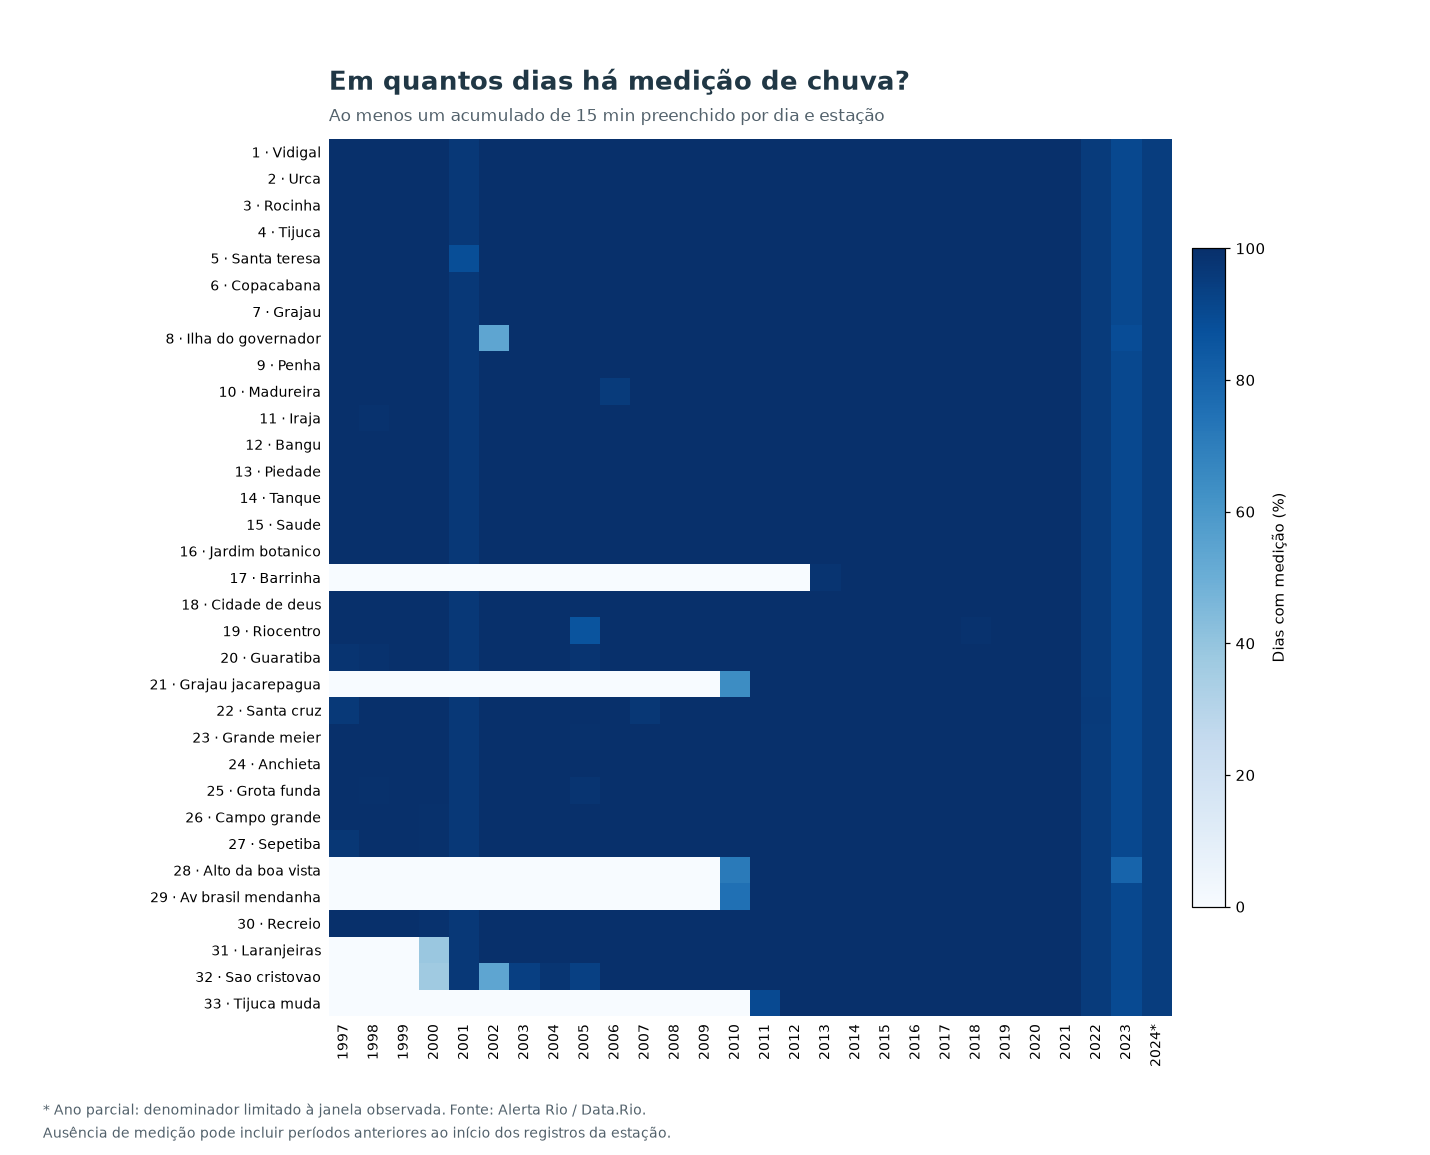

In [ ]:
import matplotlib.pyplot as plt

contagens_cobertura, limites_estacoes = [], []
for id_estacao in sorted(ids_estacoes_chuva, key=int):
    leituras_cobertura = ler_chuva_para_analise(ds.field("id_estacao") == id_estacao)
    datas_cobertura = pd.to_datetime(leituras_cobertura["data_particao"])
    dias_registrados = pd.DatetimeIndex(datas_cobertura.dropna().unique()).sort_values()
    dias_medidos = pd.DatetimeIndex(datas_cobertura[
        leituras_cobertura["acumulado_chuva_15_min"].notna()
    ].dropna().unique())
    limites_estacoes.append({
        "id_estacao": id_estacao, "Primeiro registro": dias_registrados.min(),
        "Último registro": dias_registrados.max(),
        "Dias com registros": len(dias_registrados), "Dias com medição": len(dias_medidos),
    })
    for ano, quantidade in pd.Series(dias_medidos.year).value_counts().items():
        contagens_cobertura.append({"id_estacao": id_estacao, "ano": int(ano),
                                   "dias_medidos": int(quantidade)})

resumo_cobertura_estacoes = pd.DataFrame(limites_estacoes)
inicio_cobertura = resumo_cobertura_estacoes["Primeiro registro"].min()
fim_cobertura = resumo_cobertura_estacoes["Último registro"].max()
calendario_cobertura = pd.date_range(inicio_cobertura, fim_cobertura, freq="D")
dias_por_ano = pd.Series(calendario_cobertura.year).value_counts().sort_index()
ordem_estacoes = sorted(ids_estacoes_chuva, key=int)
dias_por_estacao_ano = pd.DataFrame(contagens_cobertura).pivot(
    index="id_estacao", columns="ano", values="dias_medidos",
).reindex(index=ordem_estacoes, columns=dias_por_ano.index).fillna(0)
cobertura_estacao_ano = dias_por_estacao_ano.div(dias_por_ano, axis="columns") * 100

nomes_estacoes = estacoes.set_index("id_estacao")["estacao"]
resumo_cobertura_estacoes.insert(1, "Estação", resumo_cobertura_estacoes["id_estacao"].map(nomes_estacoes))
resumo_cobertura_estacoes["Dias com medição (%)"] = (
    100 * resumo_cobertura_estacoes["Dias com medição"] / len(calendario_cobertura)
).round(1)
resumo_cobertura_estacoes["Primeiro registro"] = resumo_cobertura_estacoes["Primeiro registro"].dt.date
resumo_cobertura_estacoes["Último registro"] = resumo_cobertura_estacoes["Último registro"].dt.date
print(f"Janela observada: {inicio_cobertura:%d/%m/%Y} a {fim_cobertura:%d/%m/%Y}.")
print("Dias considerados por ano na janela:", dias_por_ano.to_dict())
display(resumo_cobertura_estacoes)

fig_cobertura, ax_cobertura = plt.subplots(figsize=(13, 10.5))
imagem_cobertura = ax_cobertura.imshow(cobertura_estacao_ano.to_numpy(),
    aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
ax_cobertura.set_yticks(range(len(ordem_estacoes)),
    [f"{id_} · {nomes_estacoes.loc[id_]}" for id_ in ordem_estacoes], fontsize=9)
rotulos_anos = [str(ano) + ("*" if dias_por_ano.loc[ano] < pd.Timestamp(ano, 12, 31).dayofyear else "")
                for ano in dias_por_ano.index]
ax_cobertura.set_xticks(range(len(rotulos_anos)), rotulos_anos, rotation=90, fontsize=9)
ax_cobertura.tick_params(axis="both", length=0, pad=5)
ax_cobertura.set_title("Em quantos dias há medição de chuva?", loc="left",
    fontsize=17, fontweight="bold", color="#203745", pad=32)
ax_cobertura.text(0, 1.02, "Ao menos um acumulado de 15 min preenchido por dia e estação",
    transform=ax_cobertura.transAxes, fontsize=11, color="#52616b")
barra_cobertura = fig_cobertura.colorbar(imagem_cobertura, ax=ax_cobertura, pad=0.02, shrink=0.75)
barra_cobertura.set_label("Dias com medição (%)")
for borda in ax_cobertura.spines.values():
    borda.set_visible(False)
fig_cobertura.text(0.03, 0.035,
    "* Ano parcial: denominador limitado à janela observada. Fonte: Alerta Rio / Data.Rio.",
    fontsize=9, color="#52616b")
fig_cobertura.text(0.03, 0.015,
    "Ausência de medição pode incluir períodos anteriores ao início dos registros da estação.",
    fontsize=9, color="#52616b")
fig_cobertura.subplots_adjust(left=0.23, right=0.94, bottom=0.12, top=0.88)
plt.show()


**O que aparece:** algumas estações só passam a ter registros em anos posteriores, portanto a composição da rede muda ao longo da série. Em 2014–2017 e 2019–2021, todas as 33 estações têm pelo menos uma medição válida em cada dia do ano. Já em 2023, esse indicador varia de 80,0% a 90,4% entre estações; comparar totais desse ano com anos mais completos exige cuidado.

**Como ler:** cores mais escuras indicam mais dias com pelo menos uma medição, independentemente de ter chovido. Cores claras indicam menor presença de dados nessa janela, inclusive possíveis períodos anteriores ao começo dos registros. Em 2024, o denominador vai somente até 03/06 (155 dias), e não até dezembro. Mesmo uma célula com 100% não garante que todos os horários do ano estejam preenchidos. Antes de comparar totais ou extremos entre estações e anos, será necessário selecionar períodos com cobertura comparável e examinar lacunas dentro dos dias.


### Como a chuva varia entre os meses em Vidigal?

Começamos por uma estação, Vidigal (ID 1), no recorte de anos-calendário de 2014 a 2021, em que há medições em todos os dias nessa estação. Isso não garante completude dentro de cada dia. Por isso, conferimos também os intervalos e o preenchimento das leituras antes de calcular os totais mensais.

Somamos apenas o acumulado de 15 minutos em horários espaçados por pelo menos 15 minutos; não somamos acumulados de 1 h ou 24 h, cujas janelas se sobrepõem. Um mês só entra na média quando todos os horários da grade de 15 minutos têm valor preenchido. Ausências não viram zero e os meses incompletos não são extrapolados. A grade usa os horários registrados, sem conversão de fuso; eventuais saltos de relógio também fazem o mês falhar neste critério conservador. O número de meses aceitos por mês do ano é informado no gráfico.


Intervalos observados entre leituras:


,Quantidade
Intervalo,
0 days 00:15:00,280491
0 days 01:15:00,4


Meses completos incluídos: 79 de 96.


,Média mensal (mm),Mediana mensal (mm),Meses incluídos (n)
Mês,,,
Jan,93.9,90.7,6
Fev,166.5,158.3,8
Mar,161.2,132.2,7
Abr,182.1,160.3,6
Mai,82.2,99.0,7
Jun,83.9,85.0,6
Jul,61.0,42.7,6
Ago,56.2,64.7,6
Set,66.6,45.4,8


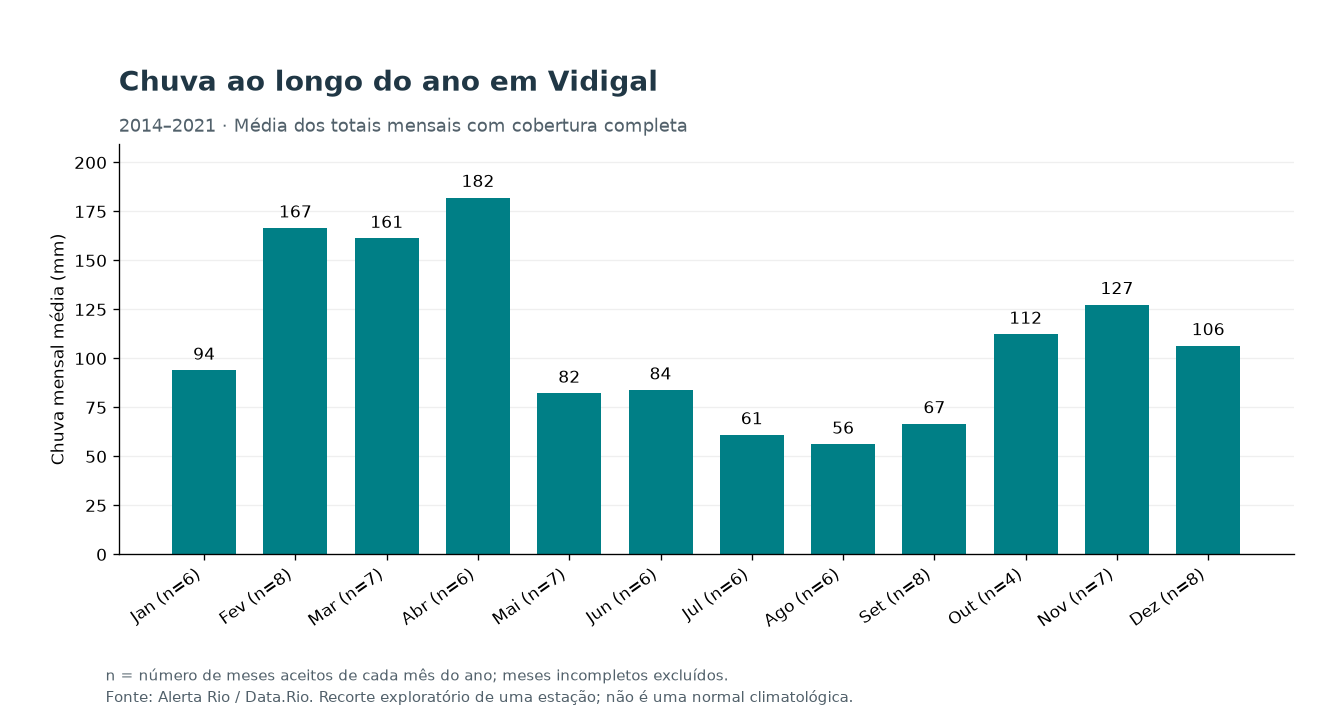

In [ ]:
import matplotlib.pyplot as plt

filtro_vidigal = (
    (ds.field("id_estacao") == "1")
    & (ds.field("data_particao") >= date(2014, 1, 1))
    & (ds.field("data_particao") <= date(2021, 12, 31))
)
chuva_vidigal = ler_chuva_com_horario(filtro_vidigal).copy()
chuva_vidigal["instante"] = pd.to_datetime(
    chuva_vidigal["data_particao"].astype(str) + " " + chuva_vidigal["horario"].astype(str)
)
serie_vidigal = chuva_vidigal.set_index("instante")["acumulado_chuva_15_min"].sort_index()
intervalos_vidigal = serie_vidigal.index.to_series().diff().dropna()
# Impede somar janelas sobrepostas ou perder horários fora da grade ao reindexar.
assert serie_vidigal.index.is_unique, "Há mais de uma leitura no mesmo horário."
assert intervalos_vidigal.ge(pd.Timedelta(minutes=15)).all(), "Há janelas de 15 min sobrepostas."
assert (serie_vidigal.index == serie_vidigal.index.floor("15min")).all(), "Há horários fora da grade."
assert serie_vidigal.dropna().ge(0).all(), "Há acumulados negativos."
print("Intervalos observados entre leituras:")
display(intervalos_vidigal.value_counts().rename_axis("Intervalo").rename("Quantidade").to_frame())

grade_vidigal = pd.date_range("2014-01-01", "2021-12-31 23:45", freq="15min")
serie_vidigal_grade = serie_vidigal.reindex(grade_vidigal)
mensal_vidigal = pd.DataFrame({
    "Total observado (mm)": serie_vidigal_grade.resample("MS").sum(min_count=1),
    "Leituras válidas": serie_vidigal_grade.resample("MS").count(),
    "Leituras esperadas": serie_vidigal_grade.resample("MS").size(),
})
meses_completos_vidigal = mensal_vidigal[
    mensal_vidigal["Leituras válidas"] == mensal_vidigal["Leituras esperadas"]
]
sazonalidade_vidigal = meses_completos_vidigal.groupby(meses_completos_vidigal.index.month)[
    "Total observado (mm)"
].agg(["mean", "median", "count"]).reindex(range(1, 13))
sazonalidade_vidigal.columns = ["Média mensal (mm)", "Mediana mensal (mm)", "Meses incluídos (n)"]
meses_abreviados = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
sazonalidade_vidigal.index = pd.Index(meses_abreviados, name="Mês")
print(f"Meses completos incluídos: {len(meses_completos_vidigal)} de {len(mensal_vidigal)}.")
display(sazonalidade_vidigal.round(1))

fig_sazonalidade, ax_sazonalidade = plt.subplots(figsize=(11, 6))
barras_sazonalidade = ax_sazonalidade.bar(range(12), sazonalidade_vidigal["Média mensal (mm)"],
    color="#007f86", width=0.7)
ax_sazonalidade.set_xticks(range(12),
    [f"{mes} (n={int(n)})" for mes, n in zip(meses_abreviados, sazonalidade_vidigal["Meses incluídos (n)"])],
    rotation=35, ha="right", fontsize=10)
ax_sazonalidade.set_ylabel("Chuva mensal média (mm)")
ax_sazonalidade.set_title("Chuva ao longo do ano em Vidigal", loc="left", fontsize=17,
    fontweight="bold", color="#203745", pad=32)
ax_sazonalidade.text(0, 1.03, "2014–2021 · Média dos totais mensais com cobertura completa",
    transform=ax_sazonalidade.transAxes, fontsize=11, color="#52616b")
ax_sazonalidade.set_axisbelow(True)
ax_sazonalidade.grid(axis="y", alpha=0.2)
ax_sazonalidade.spines[["top", "right"]].set_visible(False)
ax_sazonalidade.bar_label(barras_sazonalidade, fmt="%.0f", padding=4, fontsize=10)
ax_sazonalidade.margins(y=0.15)
fig_sazonalidade.text(0.08, 0.055, "n = número de meses aceitos de cada mês do ano; meses incompletos excluídos.",
    fontsize=9, color="#52616b")
fig_sazonalidade.text(0.08, 0.025, "Fonte: Alerta Rio / Data.Rio. Recorte exploratório de uma estação; não é uma normal climatológica.",
    fontsize=9, color="#52616b")
fig_sazonalidade.subplots_adjust(left=0.09, right=0.98, bottom=0.23, top=0.80)
plt.show()


**O que aparece:** entre os meses completos aceitos, Abr tem a maior média mensal (182.1 mm) e Ago a menor (56.2 mm). Foram aceitos 79 dos 96 meses do recorte. Esta é uma primeira descrição da sazonalidade em Vidigal, sem representar todos os bairros do Rio.

**Limitações:** as médias usam quantidades diferentes de anos conforme o mês, e a exclusão de meses incompletos pode afetar a comparação. Oito anos em uma estação não definem uma normal climatológica nem permitem concluir se os extremos ficaram mais frequentes. O resultado não envolve o cruzamento com ocorrências; essa etapa ainda exigirá compatibilizar horários entre as fontes.


### O que a cidade registrou nesse temporal

In [51]:
# Ocorrências abertas em 8 e 9 de abril de 2019, por tipo
temporal = ocorrencias[ocorrencias["data_inicio"].dt.date.isin([date(2019, 4, 8), date(2019, 4, 9)])]
print(len(temporal), "ocorrências")
temporal["pop_titulo"].value_counts().head(10)

159 ocorrências


pop_titulo
Bolsão d'água em via                    58
Queda de árvore                         41
Acidente/enguiço sem vítima             21
Alagamento                              13
Deslizamento                             5
Afundamento de pista / buraco na via     3
Acidente com vítima(s)                   3
Lâmina d'água                            3
Alagamentos e enchentes                  2
Atropelamento                            2
Name: count, dtype: int64

### Bairros e perfil

In [52]:
# Limites dos bairros: a unidade de comparação
bairros = gpd.read_parquet(BQ / "dados_mestres" / "bairro.parquet")
print(bairros.shape)
bairros.head()

(167, 12)


,id_bairro,nome,id_area_planejamento,id_regiao_planejamento,nome_regiao_planejamento,id_regiao_administrativa,nome_regiao_administrativa,subprefeitura,area,perimetro,geometry_wkt,geometry
0,3,Santo Cristo,1,1.1,Centro,1,Portuaria,Centro,1.684725e+06,6743.227885,POLYGON ((-43.194498082949565 -22.903378004069...,"POLYGON ((-43.19459 -22.90326, -43.19474 -22.9..."
1,1,Saúde,1,1.1,Centro,1,Portuaria,Centro,3.638186e+05,2646.220568,POLYGON ((-43.1811516335027 -22.89543028498111...,"POLYGON ((-43.18119 -22.89542, -43.18132 -22.8..."
2,4,Caju,1,1.1,Centro,1,Portuaria,Centro,5.347495e+06,19800.522524,POLYGON ((-43.22522241788446 -22.8746498473696...,"MULTIPOLYGON (((-43.22522 -22.87464, -43.22521..."
3,2,Gamboa,1,1.1,Centro,1,Portuaria,Centro,1.112906e+06,4612.833630,POLYGON ((-43.18791509600112 -22.8931217219090...,"POLYGON ((-43.19069 -22.89216, -43.19093 -22.8..."
4,161,Lapa,1,1.1,Centro,2,Centro,Centro,2.983266e+05,3849.181818,POLYGON ((-43.18166120770175 -22.9120798231449...,"POLYGON ((-43.18217 -22.91194, -43.18243 -22.9..."


### Onde a chuva é medida?

O mapa localiza os pluviômetros do Alerta Rio com coordenadas disponíveis sobre os limites dos bairros. Ele apresenta a distribuição espacial da rede cadastrada; não indica que todas as estações tenham leituras completas durante todo o período analisado.


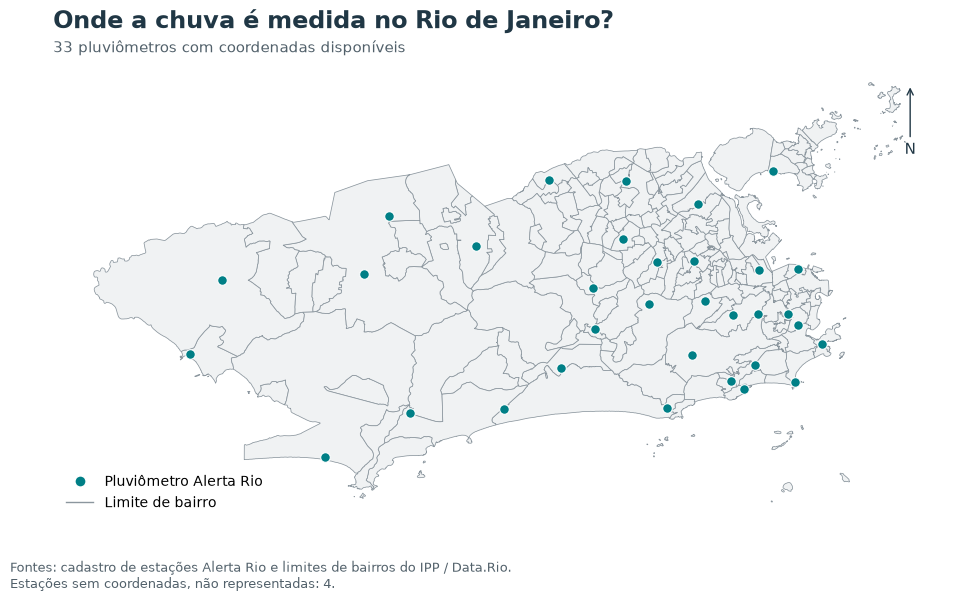

In [53]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# As quatro estações sem coordenadas continuam no cadastro, mas não entram no mapa.
estacoes_mapa = estacoes.dropna(subset=["latitude", "longitude"])
pluviometros = gpd.GeoDataFrame(
    estacoes_mapa,
    geometry=gpd.points_from_xy(estacoes_mapa["longitude"], estacoes_mapa["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:31983")  # SIRGAS 2000 / UTM 23S: projeção local em metros.
bairros_mapa = bairros.to_crs(pluviometros.crs)

fig, ax = plt.subplots(figsize=(11, 6.5))
bairros_mapa.plot(ax=ax, color="#f0f2f3", edgecolor="#8b969e", linewidth=0.55)
pluviometros.plot(ax=ax, color="#007f86", edgecolor="white", linewidth=0.8,
                 markersize=48, zorder=3)
ax.set_title("Onde a chuva é medida no Rio de Janeiro?", loc="left",
             fontsize=17, fontweight="bold", color="#203745", pad=24)
ax.text(0, 1.02, f"{len(pluviometros)} pluviômetros com coordenadas disponíveis",
        transform=ax.transAxes, fontsize=11, color="#52616b")
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", color="#007f86",
           markeredgecolor="white", markersize=8, label="Pluviômetro Alerta Rio"),
    Line2D([], [], color="#8b969e", linewidth=1, label="Limite de bairro"),
], loc="lower left", frameon=False, fontsize=10)
ax.annotate("N", xy=(0.96, 0.95), xytext=(0.96, 0.80), xycoords="axes fraction",
            ha="center", fontsize=11, color="#203745",
            arrowprops={"arrowstyle": "->", "color": "#203745"})
ax.set_axis_off()
fig.text(0.08, 0.055, "Fontes: cadastro de estações Alerta Rio e limites de bairros do IPP / Data.Rio.",
         fontsize=9, color="#52616b")
fig.text(0.08, 0.03, f"Estações sem coordenadas, não representadas: {len(estacoes) - len(pluviometros)}.",
         fontsize=9, color="#52616b")
fig.subplots_adjust(left=0.07, right=0.98, top=0.84, bottom=0.13)
plt.show()


**Leitura do mapa:** as estações não estão uniformemente espaçadas: há pontos mais próximos entre si no leste do município e maiores separações em partes do oeste. Por isso, associar ocorrências ao pluviômetro mais próximo pode envolver distâncias diferentes conforme o local. O mapa, sozinho, não mede a representatividade de cada estação nem permite concluir quais bairros têm maior risco.


In [54]:
# Censo 2022: população e domicílios por bairro
censo = gpd.read_parquet(DATA_RIO / "censo2022_bairros.parquet")
print(censo.shape)
censo.head()

(165, 18)


,nome,codbairro,regiao_adm,codra,area_plane,Total_de_pessoas_2010,Total_de_pessoas_2022,diferenca_de_pessoas,Total_de_domicilios_2022,Total_DP_2022,Total_DC,Total_DP_Ocup_2010,Total_DP_Ocup_2022,diferenca_de_DP,Shape_Length,Shape_Area,OBJECTID_1,geometry
0,Grumari,133,BARRA DA TIJUCA,24,4,167,184,17,85,85,0,44,68,24,23375.374038,9.598851e+06,1,"MULTIPOLYGON (((-43.50819 -23.03311, -43.50882..."
1,Jardim Sulacap,137,REALENGO,33,5,13062,14396,1334,6389,6387,2,4390,5481,1091,14519.328424,7.869225e+06,2,"POLYGON ((-43.37541 -22.88962, -43.37541 -22.8..."
2,Saúde,001,PORTUARIA,1,1,2749,1876,-873,1001,988,13,946,801,-145,2646.220568,3.638186e+05,3,"POLYGON ((-43.18115 -22.89543, -43.18119 -22.8..."
3,Magalhães Bastos,138,REALENGO,33,5,24430,20938,-3492,9340,9336,4,8092,8045,-47,6902.663944,1.975955e+06,4,"POLYGON ((-43.40929 -22.88269, -43.40923 -22.8..."
4,Realengo,139,REALENGO,33,5,180123,165881,-14242,72817,72801,16,59259,63429,4170,30896.866166,2.605427e+07,5,"POLYGON ((-43.43517 -22.8419, -43.43516 -22.84..."


In [55]:
# IPS 2022: nota geral e por componente, por bairro
ips = gpd.read_parquet(DATA_RIO / "ips2022_bairros.parquet")
print(ips.shape)
ips.head()

(159, 51)


,objectid,bairro,bairrostr,ra,rastr,subp,rp,rpstr,ap,apstr,ncm_2022,as_2022,m_2022,sp_2022,acb_2022,aic_2022,sbe_2022,qma_2022,di_2022,lie_2022,ti_2022,aes_2022,nhb_2022,fbe_2022,opo_2022,ips_2022,ranking_2022,cluster_2022,ipsra_med_2022,ranking_ra_2022,renda_2010,nhb_2022_mapa,fbe_2022_mapa,opo_2022_mapa,ips_2022_mapa,GlobalID,Shape__Area,Shape__Length,ncm_2022_mapa,as_2022_mapa,m_2022_mapa,sp_2022_mapa,acb_2022_mapa,aic_2022_mapa,sbe_2022_mapa,qma_2022_mapa,di_2022_mapa,lie_2022_mapa,ti_2022_mapa,aes_2022_mapa,geometry
0,1,1,Saúde,1.0,I - R.A. Portuária,Centro e Centro Histórico,11.0,1.1 - Centro,1.0,AP1,41.063350,88.112062,77.456069,89.901783,18.809620,46.224159,95.364943,54.034396,46.922688,79.403994,56.292418,4.707666,74.133316,53.608279,46.831692,58.191096,137,4,57.138098,29,759.8613,41.21 - 81.38,52.97 - 57.4,35.6 - 48.37,50.43 - 60.59,d8864e2b-aca4-4d05-9382-74d5321fd553,3.357000e+05,2900.590638,31.07 - 55.96,24.7 - 90.03,53.34 - 85.37,12.24 - 90.27,10.97 - 24.99,16.01 - 63.76,86.8 - 95.44,54.01 - 70.77,43.59 - 48.49,78.96 - 83.52,31.22 - 65.87,2.38 - 11.34,"POLYGON ((-43.1864 -22.89361, -43.18128 -22.89..."
1,2,2,Gamboa,1.0,I - R.A. Portuária,Centro e Centro Histórico,11.0,1.1 - Centro,1.0,AP1,43.138014,85.209814,54.995898,97.936843,16.291654,46.224159,82.414870,35.779938,39.839666,93.355489,66.628457,4.707666,70.320142,45.177655,51.132820,55.543539,146,4,57.138098,29,567.8586,41.21 - 81.38,38.28 - 52.97,48.37 - 53.49,50.43 - 60.59,7c088456-443d-4084-87c2-25cbc03ae91e,1.135798e+06,5774.859101,31.07 - 55.96,24.7 - 90.03,53.34 - 85.37,96.47 - 99.91,10.97 - 24.99,16.01 - 63.76,81.68 - 86.8,8.57 - 39.37,37.74 - 43.59,83.52 - 99.13,65.87 - 70.67,2.38 - 11.34,"POLYGON ((-43.18647 -22.89453, -43.18666 -22.8..."
2,3,3,Santo Cristo,1.0,I - R.A. Portuária,Centro e Centro Histórico,11.0,1.1 - Centro,1.0,AP1,46.578798,89.444286,68.645268,90.101633,27.087956,46.224159,42.763759,39.367534,35.868030,74.430838,68.960598,4.707666,73.692496,38.860852,45.991783,52.848377,153,4,57.138098,29,633.8508,41.21 - 81.38,38.28 - 52.97,35.6 - 48.37,50.43 - 60.59,9ed3acb6-966f-47b2-8b32-c59a008f11a6,1.612239e+06,7314.959711,31.07 - 55.96,24.7 - 90.03,53.34 - 85.37,12.24 - 90.27,24.99 - 29.54,16.01 - 63.76,38.56 - 79.64,39.37 - 46.3,19.6 - 37.74,45.45 - 74.7,65.87 - 70.67,2.38 - 11.34,"POLYGON ((-43.19916 -22.89713, -43.19901 -22.8..."
3,4,4,Caju,1.0,I - R.A. Portuária,Centro e Centro Histórico,11.0,1.1 - Centro,1.0,AP1,70.807500,90.917722,85.291923,91.884834,32.762381,46.224159,77.326878,58.560838,38.326463,76.511428,70.310763,4.707666,84.725495,53.718564,47.464080,61.969380,106,3,57.138098,29,469.6093,82.95 - 87.22,52.97 - 57.4,35.6 - 48.37,60.59 - 64.62,da9338ce-1aee-4645-ac5e-4a9321130d8f,5.016139e+06,20049.396390,69.34 - 82.07,90.48 - 97.39,53.34 - 85.37,91.11 - 96.47,29.54 - 34.48,16.01 - 63.76,38.56 - 79.64,54.01 - 70.77,37.74 - 43.59,74.7 - 78.96,65.87 - 70.67,2.38 - 11.34,"MULTIPOLYGON (((-43.20767 -22.86885, -43.20734..."
4,6,5,Centro,2.0,II - R.A. Centro,Centro e Centro Histórico,11.0,1.1 - Centro,1.0,AP1,52.791429,91.099535,67.881105,49.426361,38.770919,80.452172,82.533756,57.865332,50.364412,80.692383,48.394022,25.543224,65.299608,64.905545,51.248510,60.484554,120,4,60.484554,21,1613.2935,41.21 - 81.38,61.79 - 76.2,48.37 - 53.49,50.43 - 60.59,7e7c3a8e-07ac-4a44-a80a-9edf8a1d9c9d,5.886108e+06,24437.276146,31.07 - 55.96,90.48 - 97.39,53.34 - 85.37,12.24 - 90.27,34.48 - 50.13,72.09 - 83.85,81.68 - 86.8,54.01 - 70.77,48.49 - 80.58,78.96 - 83.52,31.22 - 65.87,25.34 - 50.43,"MULTIPOLYGON (((-43.17939 -22.89528, -43.1795 ..."


## 4. O que vamos tentar ver

1. **Onde e quando chove**: como a chuva se distribui pela cidade, ao longo do ano e do dia? Os dias extremos ficaram mais frequentes desde 1997?
2. **O que a chuva provoca**: que tipos de ocorrência aumentam em dias de chuva, e onde?
3. **O limiar**: a partir de quantos milímetros a chance de ocorrência passa de 50%? A prefeitura fala em 30 mm/dia.
4. **Pancada ou acumulado**: o que explica melhor cada tipo de ocorrência, chuva curta e forte (15 min, 1 h) ou acumulada (24 h, 96 h)?
5. **Bairro a bairro**: o limiar é igual na cidade toda?
6. **Quem é mais vulnerável**: os bairros que mais sofrem com a mesma chuva têm mais favelas não urbanizadas, mais domicílios inadequados, maior densidade?
7. **A resposta**: com a mesma chuva, o tempo de resposta dos órgãos muda entre regiões?

**Como juntar**: cada ocorrência tem coordenada e horário. Ligamos cada uma ao pluviômetro mais próximo e à chuva das horas anteriores, e depois ao bairro onde caiu.

**Cuidados**
- As bases do datalake vão até 2024 (ocorrências até abril).
- Ocorrência registrada não é o mesmo que alagamento real, e áreas mais monitoradas tendem a registrar mais.
- O campo de bairro das ocorrências está vazio em ~40% dos casos, então o bairro vai sair das coordenadas.

## 5. Síntese provisória e próximos passos

**O que já aprendemos.** A preparação identificou um registro de chuva com data em 2099, 99 cópias idênticas excedentes e 7.178 registros sem horário. As leituras para análise tratam a data futura e as cópias; os registros sem horário permanecem disponíveis na leitura geral, mas ficam fora dos cruzamentos que exigem horário. Os arquivos brutos foram preservados.

A cobertura não é uniforme na série inteira: algumas estações só aparecem em anos posteriores, e em 2023 a presença de ao menos uma medição por dia varia de 80,0% a 90,4% entre estações. A recomendação metodológica é comparar períodos com cobertura compatível, distinguindo ausência de medição de chuva zero. Cobertura diária completa não garante todos os horários preenchidos.

Em Vidigal, aceitamos 79 dos 96 meses de 2014–2021 pelo critério de completude das leituras de 15 minutos. Entre os meses aceitos, abril apresentou a maior média mensal (182,1 mm) e agosto a menor (56,2 mm). Essa é uma descrição de uma estação nesse recorte; a quantidade de meses incluídos varia e a seleção pode afetar as médias.

No COR, o foco inicial contém 4.882 registros de tipos de acúmulo de água e 176 de deslizamentos. Desses 5.058 registros, 4.705 receberam um bairro único pelas coordenadas, 349 ficaram fora dos polígonos e quatro estão sem coordenadas. Todos permanecem na tabela de trabalho com a situação espacial identificada.

**Limites das conclusões.** Ainda não associamos as ocorrências às medições de chuva. Portanto, não demonstramos que esses eventos foram causados por chuva, não validamos o limiar de 30 mm e não identificamos bairros mais vulneráveis. Registros do COR refletem também diferenças de monitoramento e notificação; os limites de bairros usados não reconstituem necessariamente as divisões históricas. Resultados de Vidigal não devem ser generalizados para todo o Rio.

**Próximos passos.** A associação preliminar aos pluviômetros e as distâncias estão disponíveis. Conferir a disponibilidade histórica das estações selecionadas; compatibilizar os horários entre as fontes; construir comparações com dias com e sem ocorrências sob cobertura adequada. Depois, explorar faixas de precipitação, janelas de acumulação e diferenças entre bairros. O Censo e o IPS serão integrados nessa etapa posterior. As recomendações sobre alertas ou infraestrutura dependerão dessas análises, ainda não concluídas.


## 6. Roteiro da apresentação do marco 2 (5 minutos)

| Tempo | Mensagem principal | Apoio no notebook |
|---|---|---|
| **0:00–0:45** | Pergunta central: quanta chuva está associada a problemas urbanos e como essa relação pode variar entre bairros? Apresentar as hipóteses e o escopo intermediário. | Introdução e hipóteses. |
| **0:45–1:30** | Explicar as fontes e como os dados serão ligados pelo espaço e pelo tempo. A rede tem 33 estações com coordenadas disponíveis. | Tabela de fontes e mapa “Onde a chuva é medida?”. |
| **1:30–2:15** | Mostrar por que medir cobertura é necessário. Resumir os tratamentos em uma frase, sem percorrer todas as tabelas de diagnóstico. | Mapa de calor por estação e ano; destacar que presença diária não significa completude dos horários. |
| **2:15–3:30** | Apresentar o primeiro resultado: médias mensais diferentes em Vidigal. Explicar o critério de meses completos e o significado de n. | Gráfico de sazonalidade; abril e agosto como exemplos, limitados à estação e ao recorte. |
| **3:30–4:15** | Mostrar que o cruzamento espacial é viável: 4.705 registros associados a um bairro único. Os grupos de eventos são um foco inicial, sem atribuição causal à chuva. | Resumo dos tipos e da associação aos bairros. |
| **4:15–5:00** | Dizer claramente o que ainda não foi respondido e como será investigado: disponibilidade histórica das estações selecionadas, horários, dias com e sem ocorrências e comparações entre bairros. | Síntese provisória e próximos passos. |

**Mensagem de encerramento:** temos bases definidas, critérios documentados e primeiros achados descritivos. A próxima etapa é integrar chuva e ocorrências para investigar as hipóteses, com controle da cobertura e limites explícitos de interpretação.
